# 05c. 확장 TF-IDF + 3x3 교차표 (Step 5)

목적: `05b_TF_IDF.ipynb`의 원본 seed TF-IDF를 확장한다. `04_피처엔지니어링.ipynb`에서 FastText로 생성하고 검토한 `fasttext_final_candidates.csv`를 읽어 **원본 seed + FastText 후보** 사전을 구성하고, `(stock_code, fiscal_year)` 단위 E/S/G 텍스트 피처를 만든다.

핵심 설계:
- 원본 seed는 유지하고 FastText 후보를 추가한다.
- **L2 정규화 TF-IDF 벡터**를 사용해 문서 길이의 mechanical 효과를 줄인다.
- 확장 term도 TF-IDF vocabulary의 `min_df=2`, `max_df=0.95` 컷을 동일하게 적용한다.
- E/S/G 차원 안에서 중복 term은 한 번만 합산한다.
- 3x3 (`expanded_tfidf_E/S/G` x `E/S/G_grade`) Spearman rho 교차표로 수렴타당도를 검증한다.

입력:
- `data/processed/dart_preprocessed.csv`
- `data/raw/seed_dictionary.csv`
- `data/processed/fasttext_final_candidates.csv`

출력은 baseline과 섞이지 않도록 모두 `05c_expanded_tfidf_*` 이름으로 저장한다.


## 1. import 및 경로 설정

이 노트북은 `seaborn`(heatmap), `pyarrow`(parquet 저장), `statsmodels`(회귀분석)가 필요하다. 현재 프로젝트 의존성에 없으면 아래 주석의 명령으로 설치한 뒤 다시 실행한다.


In [1]:
# 필요 패키지 미설치 시 터미널에서 실행:
# uv add seaborn pyarrow statsmodels

import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from kiwipiepy import Kiwi

try:
    import seaborn as sns
except ImportError as exc:
    raise ImportError(
        "seaborn이 설치되어 있지 않습니다. 히트맵 생성을 위해 `uv add seaborn pyarrow statsmodels` 실행 후 "
        "노트북을 다시 실행하세요."
    ) from exc

try:
    import pyarrow  # noqa: F401
except ImportError as exc:
    raise ImportError(
        "pyarrow가 설치되어 있지 않습니다. parquet 저장을 위해 `uv add seaborn pyarrow statsmodels` 실행 후 "
        "노트북을 다시 실행하세요."
    ) from exc

try:
    import statsmodels.api as sm
    from statsmodels.miscmodels.ordinal_model import OrderedModel
except ImportError as exc:
    raise ImportError(
        "statsmodels가 설치되어 있지 않습니다. OLS/Binary Logit/Ordered Logit 실행을 위해 "
        "`uv add statsmodels` 또는 `uv add seaborn pyarrow statsmodels` 실행 후 노트북을 다시 실행하세요."
    ) from exc

warnings.filterwarnings('ignore')

# 한글 폰트 자동 선택
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ['AppleGothic', 'NanumGothic', 'Malgun Gothic']:
    if font_name in available_fonts:
        rcParams['font.family'] = font_name
        break
rcParams['axes.unicode_minus'] = False

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
REPORTS_DIR = PROJECT_ROOT / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'

PREPROCESSED_CSV = DATA_PROCESSED / 'dart_preprocessed.csv'
SEED_DICTIONARY_CSV = DATA_RAW / 'seed_dictionary.csv'
FASTTEXT_FINAL_CANDIDATES_CSV = DATA_PROCESSED / 'fasttext_final_candidates.csv'
COMPANY_MASTER_CSV = DATA_RAW / 'company_master.csv'
STOPWORDS_PATH = DATA_RAW / 'stopwords_ko_esg.txt'

OUTPUT_FEATURES = DATA_PROCESSED / '05c_expanded_tfidf_features.parquet'
OUTPUT_RHO = DATA_PROCESSED / '05c_expanded_tfidf_rho_matrix.csv'
OUTPUT_PVAL = DATA_PROCESSED / '05c_expanded_tfidf_pval_matrix.csv'
OUTPUT_HEATMAP = FIGURES_DIR / '05c_expanded_tfidf_spearman_heatmap.png'
OUTPUT_DICTIONARY_REPORT = DATA_PROCESSED / '05c_expanded_tfidf_dictionary_report.csv'
OUTPUT_REGRESSION_SUMMARY = DATA_PROCESSED / '05c_expanded_tfidf_regression_summary.csv'
OUTPUT_OLS_SUMMARY = DATA_PROCESSED / '05c_expanded_tfidf_ols_summary.txt'
OUTPUT_BINARY_LOGIT_SUMMARY = DATA_PROCESSED / '05c_expanded_tfidf_binary_logit_summary.txt'
OUTPUT_ORDERED_LOGIT_SUMMARY = DATA_PROCESSED / '05c_expanded_tfidf_ordered_logit_summary.txt'

for path in [PREPROCESSED_CSV, SEED_DICTIONARY_CSV, FASTTEXT_FINAL_CANDIDATES_CSV, COMPANY_MASTER_CSV, STOPWORDS_PATH]:
    assert path.exists(), f'필수 입력 파일 누락: {path}'

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('전처리 입력:', PREPROCESSED_CSV)
print('seed dictionary:', SEED_DICTIONARY_CSV)
print('fastText candidates:', FASTTEXT_FINAL_CANDIDATES_CSV)
print('company master:', COMPANY_MASTER_CSV)
print('출력 features:', OUTPUT_FEATURES)
print('출력 heatmap:', OUTPUT_HEATMAP)


PROJECT_ROOT: /Users/home1/esg-dart-project
전처리 입력: /Users/home1/esg-dart-project/data/processed/dart_preprocessed.csv
seed dictionary: /Users/home1/esg-dart-project/data/raw/seed_dictionary.csv
fastText candidates: /Users/home1/esg-dart-project/data/processed/fasttext_final_candidates.csv
company master: /Users/home1/esg-dart-project/data/raw/company_master.csv
출력 features: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_features.parquet
출력 heatmap: /Users/home1/esg-dart-project/reports/figures/05c_expanded_tfidf_spearman_heatmap.png


## 2. 분석 파라미터

TF-IDF와 등급 숫자화 규칙을 한곳에 모아 둔다. 등급은 README 작업 흐름의 `S=6 ... D=0` 기준을 따른다.


In [2]:
ESG_DIMS = ['E', 'S', 'G']

TFIDF_MIN_DF = 2
TFIDF_MAX_DF = 0.95
TFIDF_NORM = 'l2'

GRADE_MAP = {
    'S': 6,
    'A+': 5,
    'A': 4,
    'B+': 3,
    'B': 2,
    'C': 1,
    'D': 0,
}

KEY_COLS = ['stock_code', 'fiscal_year']
STRICT_KEY_COLS = ['stock_code', 'fiscal_year', 'esg_year']
TEXT_COLS = ['expanded_tfidf_E', 'expanded_tfidf_S', 'expanded_tfidf_G']
GRADE_NUM_COLS = ['e_grade_num', 's_grade_num', 'g_grade_num']
INTEGRATED_GRADE_NUM_COL = 'esg_grade_num'
HIGH_ESG_CUTOFF = 4
REGRESSION_FEATURES = TEXT_COLS

print('TF-IDF norm:', TFIDF_NORM)
print('등급 매핑:', GRADE_MAP)


TF-IDF norm: l2
등급 매핑: {'S': 6, 'A+': 5, 'A': 4, 'B+': 3, 'B': 2, 'C': 1, 'D': 0}


## 3. 전처리 코퍼스 로드 및 키 복원

`dart_preprocessed.csv`는 03 산출물 그대로 사용한다. 이 파일에 없는 `stock_code`, `fiscal_year`는 `company_master.csv`에서 `company_name + esg_year` 유일성을 확인한 뒤 복원한다.


In [3]:
preprocessed = pd.read_csv(PREPROCESSED_CSV)
master = pd.read_csv(COMPANY_MASTER_CSV, dtype={'stock_code': 'string'})

required_preprocessed_cols = {'회사이름', 'esg_year', 'kiwi_text'}
required_master_cols = {
    'company_name', 'stock_code', 'fiscal_year', 'esg_year',
    'esg_grade', 'e_grade', 's_grade', 'g_grade'
}
assert required_preprocessed_cols <= set(preprocessed.columns), (
    f'전처리 CSV 필수 컬럼 누락: {required_preprocessed_cols - set(preprocessed.columns)}'
)
assert required_master_cols <= set(master.columns), (
    f'company_master 필수 컬럼 누락: {required_master_cols - set(master.columns)}'
)

preprocessed = preprocessed.rename(columns={'회사이름': 'company_name'}).copy()
preprocessed['company_name'] = preprocessed['company_name'].astype(str).str.strip()
preprocessed['esg_year'] = preprocessed['esg_year'].astype(int)

assert preprocessed['kiwi_text'].notna().all(), 'kiwi_text 결측이 있습니다.'
preprocessed['kiwi_text'] = preprocessed['kiwi_text'].astype(str)
assert preprocessed['kiwi_text'].str.strip().ne('').all(), 'kiwi_text 빈 문자열 행이 있습니다.'
assert preprocessed.duplicated(['company_name', 'esg_year']).sum() == 0, (
    '전처리 CSV의 company_name + esg_year 중복이 있습니다.'
)

master['company_name'] = master['company_name'].astype(str).str.strip()
master['stock_code'] = (
    master['stock_code'].astype('string').str.replace(r'\.0$', '', regex=True).str.zfill(6)
)
master['fiscal_year'] = master['fiscal_year'].astype(int)
master['esg_year'] = master['esg_year'].astype(int)

assert master.duplicated(['company_name', 'esg_year']).sum() == 0, (
    'company_master의 company_name + esg_year 중복이 있어 05에서 엄격 키 복원이 불가능합니다.'
)
assert master.duplicated(KEY_COLS).sum() == 0, 'company_master의 stock_code + fiscal_year 중복이 있습니다.'

master_key_cols = [
    'company_name', 'stock_code', 'fiscal_year', 'esg_year',
    'esg_grade', 'e_grade', 's_grade', 'g_grade'
]
corpus_df = preprocessed.merge(
    master[master_key_cols],
    on=['company_name', 'esg_year'],
    how='left',
    validate='one_to_one',
    indicator=True,
)

missing_key_rows = corpus_df.loc[corpus_df['_merge'] != 'both', ['company_name', 'esg_year']]
assert missing_key_rows.empty, 'company_master에서 키를 복원하지 못한 행이 있습니다:\n' + missing_key_rows.to_string(index=False)
corpus_df = corpus_df.drop(columns=['_merge']).sort_values(KEY_COLS).reset_index(drop=True)

assert len(corpus_df) == len(preprocessed), '키 복원 후 행 수가 달라졌습니다.'
assert corpus_df[STRICT_KEY_COLS].notna().all().all(), '복원된 키에 결측이 있습니다.'
assert corpus_df.duplicated(KEY_COLS).sum() == 0, '복원 후 stock_code + fiscal_year 중복이 있습니다.'
assert corpus_df['kiwi_text'].str.strip().ne('').all(), '키 복원 후 kiwi_text 빈 문자열 행이 있습니다.'

print('코퍼스 shape:', corpus_df.shape)
print('PK 중복 수:', corpus_df.duplicated(KEY_COLS).sum())
print('kiwi_text 결측 수:', corpus_df['kiwi_text'].isna().sum())
display(corpus_df[['company_name', 'stock_code', 'fiscal_year', 'esg_year', 'kiwi_text']].head())


코퍼스 shape: (381, 11)
PK 중복 수: 0
kiwi_text 결측 수: 0


,company_name,stock_code,fiscal_year,esg_year,kiwi_text
0,동화약품,000020,2022,2023,개요 일반 지배 기업 실체 재화 용역 근거 구분 정보 내부 목적 활용 제약 의료 기...
1,동화약품,000020,2023,2024,개요 일반 지배 기업 실체 재화 용역 근거 구분 정보 내부 목적 활용 제약 의료 기...
2,동화약품,000020,2024,2025,개요 일반 지배 기업 실체 재화 용역 근거 구분 정보 내부 목적 활용 제약 의료 기...
3,KR모터스,000040,2022,2023,개요 업계 수출 주력 유럽 경기 배기량 침체 지속 가운데 배기량 스쿠터 선호도 아시...
4,KR모터스,000040,2023,2024,개요 업계 수출 주력 유럽 경기 배기량 침체 지속 가운데 배기량 스쿠터 선호도 아시...


## 4. FastText 확장 후보 로드 및 검증

`fasttext_final_candidates.csv`는 `04_피처엔지니어링.ipynb`에서 생성한 후보 중 검토를 통과한 term을 seed별 쉼표 구분 문자열로 저장한 파일이다. E/S/G 각 10개 seed가 정확히 한 행씩 존재하는지 확인하고 후보 term을 리스트로 변환한다.


In [4]:
fasttext_final_candidates = pd.read_csv(FASTTEXT_FINAL_CANDIDATES_CSV, encoding='utf-8-sig')

required_fasttext_cols = {'dimension', 'seed_term', 'candidate'}
assert required_fasttext_cols <= set(fasttext_final_candidates.columns), (
    f'FastText 후보 CSV 필수 컬럼 누락: {required_fasttext_cols - set(fasttext_final_candidates.columns)}'
)

fasttext_final_candidates = fasttext_final_candidates[['dimension', 'seed_term', 'candidate']].copy()
fasttext_final_candidates['dimension'] = fasttext_final_candidates['dimension'].astype(str).str.strip()
fasttext_final_candidates['seed_term'] = fasttext_final_candidates['seed_term'].astype(str).str.strip()

FASTTEXT_TERM_RE = re.compile(r'^[가-힣A-Za-z]+$')


def normalize_fasttext_candidate(word: object) -> str:
    return unicodedata.normalize('NFKC', str(word)).lower().strip()


def split_fasttext_candidates(value: object) -> list[str]:
    if not isinstance(value, str) or not value.strip():
        return []
    terms = {normalize_fasttext_candidate(word) for word in value.split(',')}
    return sorted(term for term in terms if len(term) > 1 and FASTTEXT_TERM_RE.fullmatch(term))


assert len(fasttext_final_candidates) == 30, (
    f'FastText 후보 CSV는 seed별 30행이어야 합니다. 현재: {len(fasttext_final_candidates)}'
)
assert fasttext_final_candidates.groupby('dimension').size().to_dict() == {'E': 10, 'G': 10, 'S': 10}, (
    'FastText 후보 CSV는 E/S/G 각 10개 seed를 포함해야 합니다.'
)
assert fasttext_final_candidates.duplicated(['dimension', 'seed_term']).sum() == 0, (
    'FastText 후보 CSV의 dimension + seed_term 중복이 있습니다.'
)

fasttext_final_candidates['fasttext_terms'] = fasttext_final_candidates['candidate'].map(
    split_fasttext_candidates
)
assert fasttext_final_candidates['fasttext_terms'].map(len).gt(0).all(), (
    'FastText 후보가 하나도 없는 seed가 있습니다.'
)

fasttext_exploded = fasttext_final_candidates.explode('fasttext_terms')
fasttext_dimension_summary = fasttext_exploded.groupby('dimension').agg(
    seed_count=('seed_term', 'nunique'),
    candidate_pairs=('fasttext_terms', 'size'),
    unique_candidates=('fasttext_terms', 'nunique'),
)

print('FastText 후보 seed 수:', len(fasttext_final_candidates))
print('FastText 후보 pair 수:', len(fasttext_exploded))
print('FastText 고유 후보 수:', fasttext_exploded['fasttext_terms'].nunique())
display(fasttext_dimension_summary)
display(fasttext_final_candidates[['dimension', 'seed_term', 'fasttext_terms']].head())


FastText 후보 seed 수: 30
FastText 후보 pair 수: 634
FastText 고유 후보 수: 433


,seed_count,candidate_pairs,unique_candidates
dimension,,,
E,10,252,174
G,10,215,136
S,10,167,134


,dimension,seed_term,fasttext_terms
0,E,넷제로,"[mitigation, ndc, netting, renewables, roadmap..."
1,E,에너지,"[lng, mwh, 그린에너지, 기타간접배출원, 뉴에너지, 바이오에너지, 부생수소,..."
2,E,온실가스,"[scope, 감축, 기타간접배출원, 목표량, 배출, 배출량, 배출원, 온실가스인벤..."
3,E,재생에너지,"[certificate, certificates, certification, cli..."
4,E,재활용,"[발생량, 분리수거, 선순환, 순환자원인증, 재사용, 페트병, 폐거울칩, 폐유]"


## 5. TF-IDF 벡터 학습

`kiwi_text`는 이미 공백 구분 토큰 문자열이므로 `tokenizer=str.split`을 사용한다. baseline과 동일하게 `norm='l2'`, `min_df=2`, `max_df=0.95`를 적용한다.


In [5]:
corpus_texts = corpus_df['kiwi_text'].tolist()

vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    preprocessor=None,
    lowercase=False,
    norm=TFIDF_NORM,
    sublinear_tf=False,
    min_df=TFIDF_MIN_DF,
    max_df=TFIDF_MAX_DF,
)

X = vectorizer.fit_transform(corpus_texts)
vocab = vectorizer.get_feature_names_out()
vocab_to_idx = {term: idx for idx, term in enumerate(vocab)}

density = X.nnz / (X.shape[0] * X.shape[1])
print('TF-IDF matrix shape:', X.shape)
print('vocab size:', len(vocab))
print(f'density: {density:.6f}')
print('샘플 vocab:', vocab[:20])


TF-IDF matrix shape: (381, 40101)
vocab size: 40101
density: 0.043027
샘플 vocab: ['aa' 'aaa' 'aaai' 'aac' 'aachen' 'aacr' 'aaf' 'aaji' 'aak' 'aalto' 'aam'
 'aap' 'aaps' 'aasld' 'ab' 'abadi' 'abang' 'abb' 'abbott' 'abbvie']


## 6. L2 정규화 검증

각 문서 벡터의 L2 norm이 1인지 확인한다. 모든 문서에 TF-IDF vocabulary에 남은 토큰이 있어야 이 검증이 통과한다.


In [6]:
row_norms = np.sqrt(X.power(2).sum(axis=1)).A1
bad_norm_mask = ~np.isclose(row_norms, 1.0)

print(pd.Series(row_norms).describe().to_string())
if bad_norm_mask.any():
    display(corpus_df.loc[bad_norm_mask, ['company_name', 'stock_code', 'fiscal_year', 'esg_year']].head())

assert np.allclose(row_norms, 1.0), 'L2 정규화 sanity check 실패: 일부 문서 벡터 norm이 1이 아닙니다.'
print('L2 정규화 검증 통과:', np.allclose(row_norms, 1.0))


count    3.810000e+02
mean     1.000000e+00
std      2.549381e-15
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
L2 정규화 검증 통과: True


## 7. 원본 seed + FastText 후보 TF-IDF vocab 매칭

원본 `seed_dictionary.csv`의 `seed_term`, `pattern`을 baseline과 동일하게 재토큰화한다. 여기에 검토 완료 FastText 후보를 합쳐 확장 사전을 만들고 TF-IDF vocabulary에 남은 term과 제거된 term을 확인한다.


In [7]:
seed_dictionary = pd.read_csv(SEED_DICTIONARY_CSV)
assert {'dimension', 'seed_term', 'pattern'} <= set(seed_dictionary.columns), 'seed_dictionary 필수 컬럼 누락'
assert len(seed_dictionary) == 30, f'seed_dictionary는 30행이어야 합니다. 현재: {len(seed_dictionary)}'
assert seed_dictionary.groupby('dimension').size().to_dict() == {'E': 10, 'G': 10, 'S': 10}, (
    'seed_dictionary는 E/S/G 각 10개여야 합니다.'
)
assert seed_dictionary.duplicated(['dimension', 'seed_term']).sum() == 0, (
    'seed_dictionary의 dimension + seed_term 중복이 있습니다.'
)

base_seed_keys = set(seed_dictionary[['dimension', 'seed_term']].itertuples(index=False, name=None))
fasttext_seed_keys = set(
    fasttext_final_candidates[['dimension', 'seed_term']].itertuples(index=False, name=None)
)
assert base_seed_keys == fasttext_seed_keys, (
    'seed_dictionary와 FastText 후보 CSV의 dimension + seed_term 구성이 다릅니다. '
    f'원본에만 존재: {sorted(base_seed_keys - fasttext_seed_keys)}, '
    f'FastText 후보에만 존재: {sorted(fasttext_seed_keys - base_seed_keys)}'
)

with STOPWORDS_PATH.open('r', encoding='utf-8') as f:
    stopwords = {
        unicodedata.normalize('NFKC', line.strip()).lower()
        for line in f
        if line.strip() and not line.strip().startswith('#')
    }
stopwords |= {'i', 'ii', 'iii', 'iv', 'v', 'vi', 'vii', 'viii', 'ix', 'x', 'xi', 'xii'}

kiwi = Kiwi()
KEEP_POS_PREFIXES = ('N', 'V')
KEEP_POS_TAGS = {'SL'}
TOKEN_RE = re.compile(r'^[가-힣A-Za-z]+$')


def normalize_word(word: object) -> str:
    return unicodedata.normalize('NFKC', str(word)).lower().strip()


def tokenize_seed_phrase(phrase: object) -> list[str]:
    if not isinstance(phrase, str) or not phrase.strip():
        return []

    phrase = normalize_word(phrase)
    out: set[str] = set()

    compact = re.sub(r'[^가-힣A-Za-z]+', '', phrase)
    if len(compact) > 1 and TOKEN_RE.fullmatch(compact):
        out.add(compact)

    for part in re.split(r'[^가-힣A-Za-z]+', phrase):
        if len(part) > 1 and TOKEN_RE.fullmatch(part):
            out.add(part)

    for token in kiwi.tokenize(phrase):
        word = normalize_word(token.form)
        if len(word) <= 1 or not TOKEN_RE.fullmatch(word):
            continue
        if not (token.tag.startswith(KEEP_POS_PREFIXES) or token.tag in KEEP_POS_TAGS):
            continue
        out.add(word)

    return sorted(out)


def original_seed_candidate_terms(row: pd.Series) -> list[str]:
    phrases = [row['seed_term']]
    if isinstance(row.get('pattern'), str):
        phrases.extend(row['pattern'].split('|'))

    terms: list[str] = []
    for phrase in phrases:
        terms.extend(tokenize_seed_phrase(phrase))

    return sorted({term for term in terms if term not in stopwords})


seed_dictionary['original_candidate_terms'] = seed_dictionary.apply(
    original_seed_candidate_terms,
    axis=1,
)
expanded_dictionary = seed_dictionary.merge(
    fasttext_final_candidates[['dimension', 'seed_term', 'fasttext_terms']],
    on=['dimension', 'seed_term'],
    how='left',
    validate='one_to_one',
)


def combine_expanded_terms(row: pd.Series) -> list[str]:
    return sorted({
        *row['original_candidate_terms'],
        *row['fasttext_terms'],
    } - stopwords)


expanded_dictionary['candidate_terms'] = expanded_dictionary.apply(combine_expanded_terms, axis=1)
expanded_dictionary['found_terms'] = expanded_dictionary['candidate_terms'].map(
    lambda terms: [term for term in terms if term in vocab_to_idx]
)
expanded_dictionary['missing_terms'] = expanded_dictionary['candidate_terms'].map(
    lambda terms: [term for term in terms if term not in vocab_to_idx]
)
expanded_dictionary['original_candidate_count'] = expanded_dictionary['original_candidate_terms'].map(len)
expanded_dictionary['fasttext_candidate_count'] = expanded_dictionary['fasttext_terms'].map(len)
expanded_dictionary['expanded_candidate_count'] = expanded_dictionary['candidate_terms'].map(len)
expanded_dictionary['matched_vocab_count'] = expanded_dictionary['found_terms'].map(len)

expanded_match_report = expanded_dictionary[
    [
        'dimension', 'seed_term', 'pattern',
        'original_candidate_terms', 'fasttext_terms', 'candidate_terms',
        'found_terms', 'missing_terms',
        'original_candidate_count', 'fasttext_candidate_count',
        'expanded_candidate_count', 'matched_vocab_count',
    ]
].copy()

found_by_dim = {
    dim: sorted({
        term
        for terms in expanded_dictionary.loc[expanded_dictionary['dimension'] == dim, 'found_terms']
        for term in terms
    })
    for dim in ESG_DIMS
}
missing_by_dim = {
    dim: sorted({
        term
        for terms in expanded_dictionary.loc[expanded_dictionary['dimension'] == dim, 'missing_terms']
        for term in terms
    })
    for dim in ESG_DIMS
}

print('원본 seed 재토큰화 term 수:', sum(expanded_dictionary['original_candidate_count']))
print('FastText 후보 term 수:', sum(expanded_dictionary['fasttext_candidate_count']))
print('확장 후 seed별 term 수 합계:', sum(expanded_dictionary['expanded_candidate_count']))
print('dimension별 vocab 매칭 고유 term 수:', {dim: len(terms) for dim, terms in found_by_dim.items()})
print('dimension별 missing 고유 term 수:', {dim: len(terms) for dim, terms in missing_by_dim.items()})

missing_seed_rows = expanded_match_report[expanded_match_report['matched_vocab_count'] == 0]
if not missing_seed_rows.empty:
    print('경고: vocab에 매칭되는 term이 하나도 없는 seed가 있습니다. 해당 seed는 0점 처리됩니다.')
    display(missing_seed_rows)

display(expanded_match_report)


원본 seed 재토큰화 term 수: 88
FastText 후보 term 수: 634
확장 후 seed별 term 수 합계: 722
dimension별 vocab 매칭 고유 term 수: {'E': 185, 'S': 138, 'G': 131}
dimension별 missing 고유 term 수: {'E': 16, 'S': 21, 'G': 37}


,dimension,seed_term,pattern,original_candidate_terms,fasttext_terms,candidate_terms,found_terms,missing_terms,original_candidate_count,fasttext_candidate_count,expanded_candidate_count,matched_vocab_count
0,E,탄소,탄소,[탄소],"[cdp, sbti, 감축, 개질수소, 기타간접배출원, 기후, 로드맵, 목표량, 배...","[cdp, sbti, 감축, 개질수소, 기타간접배출원, 기후, 로드맵, 목표량, 배...","[cdp, sbti, 감축, 개질수소, 기타간접배출원, 기후, 로드맵, 목표량, 배...",[수소혼소발전],1,18,19,18
1,E,온실가스,온실가스|GHG,"[ghg, 온실가스]","[scope, 감축, 기타간접배출원, 목표량, 배출, 배출량, 배출원, 온실가스인벤...","[ghg, scope, 감축, 기타간접배출원, 목표량, 배출, 배출량, 배출원, 온...","[scope, 감축, 기타간접배출원, 목표량, 배출, 배출량, 배출원, 온실가스, ...",[ghg],2,11,13,12
2,E,탄소중립,탄소중립,"[중립, 탄소, 탄소중립]","[cdp, sbti, 감축, 개질수소, 기타간접배출원, 기후, 로드맵, 목표량, 물...","[cdp, sbti, 감축, 개질수소, 기타간접배출원, 기후, 로드맵, 목표량, 물...","[cdp, sbti, 감축, 개질수소, 기타간접배출원, 기후, 로드맵, 목표량, 물...","[수소개질, 수소혼소발전, 탄소중립]",3,23,26,23
3,E,넷제로,넷제로|net zero|net-zero,"[net, netzero, zero, 넷제로]","[mitigation, ndc, netting, renewables, roadmap...","[mitigation, ndc, net, netting, netzero, renew...","[ndc, net, netting, netzero, roadmap, sbti, ze...","[mitigation, renewables, 수소혼소발전]",4,10,14,11
4,E,재생에너지,재생에너지|renewable energy,"[energy, renewable, renewableenergy, 에너지, 재생, ...","[certificate, certificates, certification, cli...","[certificate, certificates, certification, cli...","[certificate, certificates, certification, cli...","[cogeneration, mitigation, renewableenergy, re...",6,31,37,31
5,E,에너지,에너지,[에너지],"[lng, mwh, 그린에너지, 기타간접배출원, 뉴에너지, 바이오에너지, 부생수소,...","[lng, mwh, 그린에너지, 기타간접배출원, 뉴에너지, 바이오에너지, 부생수소,...","[lng, mwh, 그린에너지, 기타간접배출원, 바이오에너지, 부생수소, 수소혼소,...","[뉴에너지, 수소혼소발전]",1,21,22,20
6,E,전력,전력|전력사용량,"[사용량, 전력, 전력사용량]","[gwh, kwh, mwh, scope, toe, twh, 감축, 개질수소, 기타간...","[gwh, kwh, mwh, scope, toe, twh, 감축, 개질수소, 기타간...","[gwh, kwh, mwh, scope, toe, 감축, 개질수소, 기타간접배출원,...","[twh, 수소혼소발전, 전력사용량]",3,53,56,53
7,E,폐기물,폐기물,[폐기물],"[감량, 매립, 발생량, 보관장, 분리수거, 분진, 수거, 슬러지, 쓰레기, 오니,...","[감량, 매립, 발생량, 보관장, 분리수거, 분진, 수거, 슬러지, 쓰레기, 오니,...","[감량, 매립, 발생량, 보관장, 분리수거, 분진, 수거, 슬러지, 쓰레기, 오니,...",[],1,17,18,18
8,E,재활용,재활용|자원순환,"[순환, 자원, 자원순환, 재활용, 활용]","[발생량, 분리수거, 선순환, 순환자원인증, 재사용, 페트병, 폐거울칩, 폐유]","[발생량, 분리수거, 선순환, 순환, 순환자원인증, 자원, 자원순환, 재사용, 재활...","[발생량, 분리수거, 선순환, 순환, 순환자원인증, 자원, 재사용, 재활용, 페트병...",[자원순환],5,8,13,12
9,E,폐수,폐수|수질|물관리,"[물관리, 수질, 폐수]","[ppm, toc, 광유류, 규조류, 농도, 누출, 다이옥신, 대기, 발생량, 방류...","[ppm, toc, 광유류, 규조류, 농도, 누출, 다이옥신, 대기, 물관리, 발생...","[ppm, toc, 규조류, 농도, 누출, 다이옥신, 대기, 발생량, 방류, 배출,...","[광유류, 물관리, 중화조]",3,60,63,60


## 8. Dimension별 확장 TF-IDF 합산

같은 dimension 안에서 원본 seed와 FastText 후보가 동일 vocabulary term에 매칭될 수 있으므로, dimension별 고유 term을 만든 뒤 한 번만 합산한다.


In [8]:
def sum_seed_columns(X_sparse, vocab_index: dict[str, int], seed_words: list[str]) -> np.ndarray:
    col_indices = [vocab_index[word] for word in sorted(set(seed_words)) if word in vocab_index]
    if not col_indices:
        return np.zeros(X_sparse.shape[0], dtype=float)
    return np.asarray(X_sparse[:, col_indices].sum(axis=1)).ravel()


tfidf_scores = {
    dim: sum_seed_columns(X, vocab_to_idx, found_by_dim[dim])
    for dim in ESG_DIMS
}

for dim in ESG_DIMS:
    print(f'{dim}: matched terms={len(found_by_dim[dim])}, score mean={tfidf_scores[dim].mean():.6f}, max={tfidf_scores[dim].max():.6f}')


E: matched terms=185, score mean=0.219324, max=1.073032
S: matched terms=138, score mean=0.142964, max=0.522304
G: matched terms=131, score mean=0.205170, max=0.687629


## 9. 확장 피처 테이블 조립 및 분포 확인

최종 피처는 `company_name`, `stock_code`, `fiscal_year`, `esg_year`와 `expanded_tfidf_E/S/G`만 포함한다. 저장 전 PK 유일성을 다시 확인한다.


,company_name,stock_code,fiscal_year,esg_year,expanded_tfidf_E,expanded_tfidf_S,expanded_tfidf_G
0,동화약품,000020,2022,2023,0.067580,0.101230,0.169617
1,동화약품,000020,2023,2024,0.062698,0.091601,0.153246
2,동화약품,000020,2024,2025,0.074339,0.147912,0.114370
3,KR모터스,000040,2022,2023,0.062948,0.028060,0.050655
4,KR모터스,000040,2023,2024,0.043374,0.033873,0.040319


,expanded_tfidf_E,expanded_tfidf_S,expanded_tfidf_G
count,381.000000,381.000000,381.000000
mean,0.219324,0.142964,0.205170
std,0.229946,0.091404,0.116958
min,0.000000,0.007175,0.039473
25%,0.050141,0.076936,0.117364
50%,0.129248,0.127230,0.180871
75%,0.320360,0.186063,0.258912
max,1.073032,0.522304,0.687629


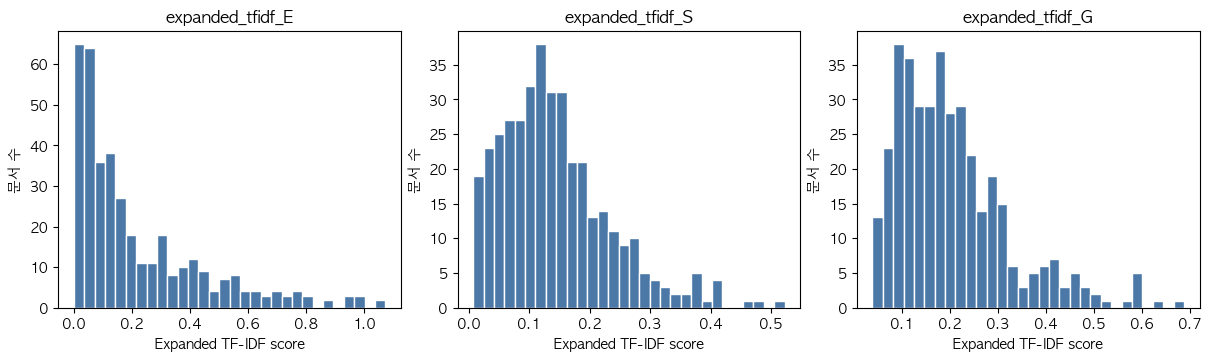

In [9]:
features = pd.DataFrame({
    'company_name': corpus_df['company_name'],
    'stock_code': corpus_df['stock_code'],
    'fiscal_year': corpus_df['fiscal_year'],
    'esg_year': corpus_df['esg_year'],
    'expanded_tfidf_E': tfidf_scores['E'],
    'expanded_tfidf_S': tfidf_scores['S'],
    'expanded_tfidf_G': tfidf_scores['G'],
})

assert len(features) == len(corpus_df), 'features 행 수가 corpus_df와 다릅니다.'
assert features[STRICT_KEY_COLS].notna().all().all(), 'features 키 컬럼에 결측이 있습니다.'
assert features.duplicated(KEY_COLS).sum() == 0, 'features의 stock_code + fiscal_year 중복이 있습니다.'
assert features[TEXT_COLS].notna().all().all(), 'TF-IDF 피처에 결측이 있습니다.'

display(features.head())
display(features[TEXT_COLS].describe())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, col in zip(axes, TEXT_COLS):
    ax.hist(features[col], bins=30, color='#4C78A8', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('Expanded TF-IDF score')
    ax.set_ylabel('문서 수')
plt.show()


## 10. ESG 등급 데이터 준비 및 merge

`company_master.csv`의 등급을 최종 PK인 `stock_code x fiscal_year x esg_year`로 붙인다. 통합 ESG 등급과 E/S/G 등급은 숫자 서열로 변환한다.


In [10]:
grades = master[
    ['company_name', 'stock_code', 'fiscal_year', 'esg_year', 'esg_grade', 'e_grade', 's_grade', 'g_grade']
].copy()
grades = grades.sort_values(KEY_COLS).reset_index(drop=True)

for col in ['esg_grade', 'e_grade', 's_grade', 'g_grade']:
    grades[col] = grades[col].astype(str).str.strip()

grades['esg_grade_num'] = grades['esg_grade'].map(GRADE_MAP)
grades['e_grade_num'] = grades['e_grade'].map(GRADE_MAP)
grades['s_grade_num'] = grades['s_grade'].map(GRADE_MAP)
grades['g_grade_num'] = grades['g_grade'].map(GRADE_MAP)
grades['high_esg'] = (grades['esg_grade_num'] >= HIGH_ESG_CUTOFF).astype(int)

assert grades.duplicated(STRICT_KEY_COLS).sum() == 0, 'grades의 strict key 중복이 있습니다.'
assert grades['esg_grade_num'].notna().all(), '숫자화되지 않은 통합 ESG 등급이 있습니다.'
assert grades[GRADE_NUM_COLS].notna().all().all(), '숫자화되지 않은 E/S/G 등급이 있습니다.'
assert set(grades['high_esg'].dropna().unique()) == {0, 1}, 'high_esg가 0/1 두 클래스를 모두 가져야 합니다.'

merged = features.merge(
    grades[STRICT_KEY_COLS + ['esg_grade', 'e_grade', 's_grade', 'g_grade', 'esg_grade_num', 'high_esg'] + GRADE_NUM_COLS],
    on=STRICT_KEY_COLS,
    how='left',
    validate='one_to_one',
    indicator=True,
)

match_rate = (merged['_merge'] == 'both').mean()
grade_attached_rate = merged[[INTEGRATED_GRADE_NUM_COL] + GRADE_NUM_COLS].notna().all(axis=1).mean()
assert match_rate == 1.0, '등급 merge 누락 행이 있습니다.'
assert grade_attached_rate == 1.0, '통합 ESG 및 E/S/G 숫자 등급이 붙지 않은 행이 있습니다.'
assert set(merged['high_esg'].dropna().unique()) == {0, 1}, 'merged high_esg가 0/1 두 클래스를 모두 가져야 합니다.'
merged = merged.drop(columns=['_merge'])

print(f'등급 매칭률: {match_rate:.1%} ({int(match_rate * len(features))}/{len(features)})')
print(f'통합 ESG 및 E/S/G 등급 부착률: {grade_attached_rate:.1%}')
print('high_esg 분포 (A 이상=1):')
print(merged['high_esg'].value_counts().sort_index().to_string())
display(merged[['company_name', 'stock_code', 'fiscal_year', 'esg_year'] + TEXT_COLS + ['esg_grade_num', 'high_esg'] + GRADE_NUM_COLS].head())
display(merged[['esg_grade', 'e_grade', 's_grade', 'g_grade']].apply(pd.Series.value_counts).fillna(0).astype(int))


등급 매칭률: 100.0% (381/381)
통합 ESG 및 E/S/G 등급 부착률: 100.0%
high_esg 분포 (A 이상=1):
high_esg
0    229
1    152


,company_name,stock_code,fiscal_year,esg_year,expanded_tfidf_E,expanded_tfidf_S,expanded_tfidf_G,esg_grade_num,high_esg,e_grade_num,s_grade_num,g_grade_num
0,동화약품,000020,2022,2023,0.067580,0.101230,0.169617,1,0,1,2,1
1,동화약품,000020,2023,2024,0.062698,0.091601,0.153246,1,0,2,2,1
2,동화약품,000020,2024,2025,0.074339,0.147912,0.114370,1,0,2,1,1
3,KR모터스,000040,2022,2023,0.062948,0.028060,0.050655,0,0,0,0,0
4,KR모터스,000040,2023,2024,0.043374,0.033873,0.040319,0,0,0,0,0


,esg_grade,e_grade,s_grade,g_grade
A,123,130,97,85
A+,29,42,136,18
B,36,29,14,48
B+,76,74,33,99
C,53,64,34,68
D,64,42,67,63


## 11. 3x3 Spearman 교차표 계산

`expanded_tfidf_E/S/G`와 `e/s/g_grade_num`의 모든 조합에 대해 Spearman 순위상관계수와 p-value를 계산한다.


In [11]:
rho_matrix = pd.DataFrame(index=TEXT_COLS, columns=GRADE_NUM_COLS, dtype=float)
pval_matrix = pd.DataFrame(index=TEXT_COLS, columns=GRADE_NUM_COLS, dtype=float)

spearman_data = merged.dropna(subset=TEXT_COLS + GRADE_NUM_COLS).copy()
assert len(spearman_data) > 0, 'Spearman 계산 가능한 데이터가 없습니다.'

for text_col in TEXT_COLS:
    for grade_col in GRADE_NUM_COLS:
        pair = spearman_data[[text_col, grade_col]].dropna()
        if pair[text_col].nunique() < 2 or pair[grade_col].nunique() < 2:
            rho, pval = np.nan, np.nan
        else:
            rho, pval = spearmanr(pair[text_col], pair[grade_col])
        rho_matrix.loc[text_col, grade_col] = rho
        pval_matrix.loc[text_col, grade_col] = pval

print('Spearman rho matrix')
display(rho_matrix)
print('p-value matrix')
display(pval_matrix)


Spearman rho matrix


,e_grade_num,s_grade_num,g_grade_num
expanded_tfidf_E,0.362825,0.297675,0.195364
expanded_tfidf_S,0.423759,0.428846,0.424119
expanded_tfidf_G,0.274823,0.299901,0.336969


p-value matrix


,e_grade_num,s_grade_num,g_grade_num
expanded_tfidf_E,2.684230e-13,3.100755e-09,1.241033e-04
expanded_tfidf_S,4.907129e-18,1.776683e-18,4.569269e-18
expanded_tfidf_G,4.979889e-08,2.334533e-09,1.435167e-11


## 12. Spearman 교차표 heatmap

색은 rho 값을 나타내며, 각 셀 annotation에는 rho와 유의수준 별표를 함께 표기한다.


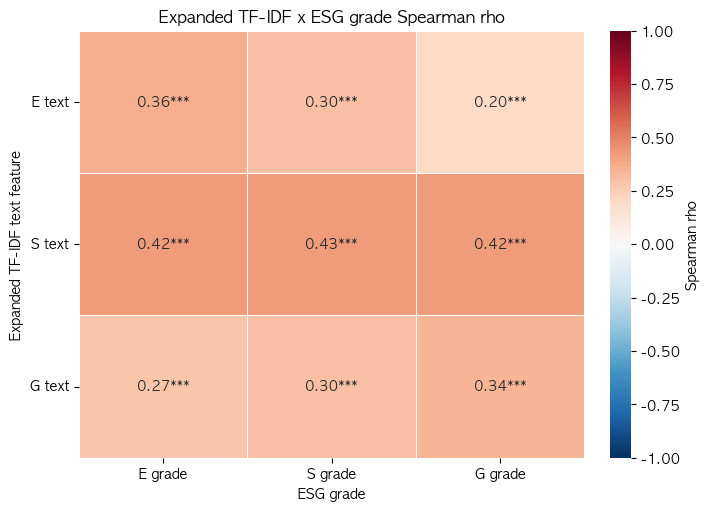

heatmap 저장: /Users/home1/esg-dart-project/reports/figures/05c_expanded_tfidf_spearman_heatmap.png


In [12]:
def pvalue_stars(pval: float) -> str:
    if pd.isna(pval):
        return ''
    if pval < 0.001:
        return '***'
    if pval < 0.01:
        return '**'
    if pval < 0.05:
        return '*'
    return ''


annot = rho_matrix.copy().astype(object)
for row in rho_matrix.index:
    for col in rho_matrix.columns:
        rho = rho_matrix.loc[row, col]
        pval = pval_matrix.loc[row, col]
        annot.loc[row, col] = 'NA' if pd.isna(rho) else f'{rho:.2f}{pvalue_stars(pval)}'

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
sns.heatmap(
    rho_matrix.astype(float),
    annot=annot,
    fmt='',
    center=0,
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Spearman rho'},
    ax=ax,
)
ax.set_title('Expanded TF-IDF x ESG grade Spearman rho')
ax.set_xlabel('ESG grade')
ax.set_ylabel('Expanded TF-IDF text feature')
ax.set_xticklabels(['E grade', 'S grade', 'G grade'])
ax.set_yticklabels(['E text', 'S text', 'G text'], rotation=0)

fig.savefig(OUTPUT_HEATMAP, dpi=200, bbox_inches='tight')
plt.show()

print('heatmap 저장:', OUTPUT_HEATMAP)


## 13. Spearman 해석 가이드

- **대각선이 강하고 비대각선이 약함**: 확장 사전이 차원별 텍스트 신호를 비교적 잘 분리한 패턴이다.
- **비대각선까지 강함**: 공시량, 기업 규모, 전반적 ESG maturity 효과가 함께 반영될 수 있다.
- baseline인 `05b_TF_IDF.ipynb`의 3x3 교차표와 비교해 FastText 확장이 차원 분리를 개선했는지 확인한다.
- 아래 회귀는 통제변수 없는 baseline 검증이다. 인과효과가 아니라 텍스트 공시 강도와 ESG 등급 간 연관성으로 해석한다.


실행 후 위 교차표를 `05b_TF_IDF.ipynb`의 seed-only 결과와 비교해 기록한다.


## 14. 회귀 패널 구성

통합 ESG 등급(`esg_grade_num`)을 종속변수로 두고, `expanded_tfidf_E`, `expanded_tfidf_S`, `expanded_tfidf_G`를 함께 투입한다. Binary Logit은 A 이상(`esg_grade_num >= 4`)을 우수 그룹으로 정의한다.


In [13]:
regression_panel = merged.dropna(
    subset=[INTEGRATED_GRADE_NUM_COL, 'high_esg'] + REGRESSION_FEATURES
).copy()

assert len(regression_panel) > 0, '회귀에 사용할 행이 없습니다.'
assert regression_panel[INTEGRATED_GRADE_NUM_COL].notna().all(), 'esg_grade_num 결측이 있습니다.'
assert regression_panel['high_esg'].notna().all(), 'high_esg 결측이 있습니다.'
assert set(regression_panel['high_esg'].unique()) == {0, 1}, 'Binary Logit을 위해 high_esg는 0/1 두 클래스를 모두 가져야 합니다.'
assert regression_panel[REGRESSION_FEATURES].notna().all().all(), '회귀 설명변수에 결측이 있습니다.'

print('회귀 패널 shape:', regression_panel.shape)
print('통합 ESG 등급 분포:')
print(regression_panel['esg_grade'].value_counts().sort_index().to_string())
print('\nhigh_esg 분포 (A 이상=1):')
print(regression_panel['high_esg'].value_counts().sort_index().to_string())
display(regression_panel[['company_name', 'stock_code', 'fiscal_year', 'esg_grade', 'esg_grade_num', 'high_esg'] + REGRESSION_FEATURES].head())


회귀 패널 shape: (381, 16)
통합 ESG 등급 분포:
esg_grade
A     123
A+     29
B      36
B+     76
C      53
D      64

high_esg 분포 (A 이상=1):
high_esg
0    229
1    152


,company_name,stock_code,fiscal_year,esg_grade,esg_grade_num,high_esg,expanded_tfidf_E,expanded_tfidf_S,expanded_tfidf_G
0,동화약품,000020,2022,C,1,0,0.067580,0.101230,0.169617
1,동화약품,000020,2023,C,1,0,0.062698,0.091601,0.153246
2,동화약품,000020,2024,C,1,0,0.074339,0.147912,0.114370
3,KR모터스,000040,2022,D,0,0,0.062948,0.028060,0.050655
4,KR모터스,000040,2023,D,0,0,0.043374,0.033873,0.040319


## 15. OLS 회귀분석

OLS는 통합 ESG 등급을 연속형 점수처럼 본 baseline이다. `HC3` robust standard error를 사용한다.


In [14]:
ols_X = sm.add_constant(regression_panel[REGRESSION_FEATURES], has_constant='add')
ols_y = regression_panel[INTEGRATED_GRADE_NUM_COL]

ols_result = sm.OLS(ols_y, ols_X).fit(cov_type='HC3')
print(ols_result.summary())

ols_coef_table = pd.DataFrame({
    'term': ols_result.params.index,
    'coef': ols_result.params.values,
    'std_err': ols_result.bse.values,
    'p_value': ols_result.pvalues.values,
})
ols_coef_table['model'] = 'OLS'
ols_coef_table['metric_name'] = 'r_squared'
ols_coef_table['metric_value'] = ols_result.rsquared
display(ols_coef_table)


                            OLS Regression Results                            
Dep. Variable:          esg_grade_num   R-squared:                       0.208
Model:                            OLS   Adj. R-squared:                  0.202
Method:                 Least Squares   F-statistic:                     41.30
Date:                Sun, 31 May 2026   Prob (F-statistic):           4.27e-23
Time:                        18:11:44   Log-Likelihood:                -680.28
No. Observations:                 381   AIC:                             1369.
Df Residuals:                     377   BIC:                             1384.
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                1.2633      0.171  

,term,coef,std_err,p_value,model,metric_name,metric_value
0,const,1.263288,0.171127,1.557440e-13,OLS,r_squared,0.208123
1,expanded_tfidf_E,1.238433,0.319882,1.081539e-04,OLS,r_squared,0.208123
2,expanded_tfidf_S,5.712861,0.996396,9.836523e-09,OLS,r_squared,0.208123
3,expanded_tfidf_G,1.202832,0.780208,1.231511e-01,OLS,r_squared,0.208123


실행 후 OLS의 계수 방향, 유의성, R-squared를 seed-only 결과와 비교한다.


## 16. Binary Logit 회귀분석

Binary Logit은 A 이상 여부(`high_esg`)를 종속변수로 둔다. 계수와 함께 odds ratio를 출력한다.


In [15]:
binary_X = sm.add_constant(regression_panel[REGRESSION_FEATURES], has_constant='add')
binary_y = regression_panel['high_esg']

binary_logit_result = sm.Logit(binary_y, binary_X).fit(disp=False)
print(binary_logit_result.summary())

binary_coef_table = pd.DataFrame({
    'term': binary_logit_result.params.index,
    'coef': binary_logit_result.params.values,
    'std_err': binary_logit_result.bse.values,
    'p_value': binary_logit_result.pvalues.values,
})
binary_coef_table['odds_ratio'] = np.exp(binary_coef_table['coef'])
binary_coef_table['model'] = 'Binary Logit'
binary_coef_table['metric_name'] = 'pseudo_r_squared'
binary_coef_table['metric_value'] = binary_logit_result.prsquared
display(binary_coef_table)


                           Logit Regression Results                           
Dep. Variable:               high_esg   No. Observations:                  381
Model:                          Logit   Df Residuals:                      377
Method:                           MLE   Df Model:                            3
Date:                Sun, 31 May 2026   Pseudo R-squ.:                 0.08788
Time:                        18:11:44   Log-Likelihood:                -233.74
converged:                       True   LL-Null:                       -256.25
Covariance Type:            nonrobust   LLR p-value:                 9.081e-10
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.7971      0.274     -6.550      0.000      -2.335      -1.259
expanded_tfidf_E     1.3568      0.526      2.582      0.010       0.327       2.387
expanded_tfidf_S     5.9145 

,term,coef,std_err,p_value,odds_ratio,model,metric_name,metric_value
0,const,-1.797104,0.274370,5.756814e-11,0.165778,Binary Logit,pseudo_r_squared,0.087878
1,expanded_tfidf_E,1.356768,0.525521,9.829767e-03,3.883622,Binary Logit,pseudo_r_squared,0.087878
2,expanded_tfidf_S,5.914489,1.555182,1.429047e-04,370.365141,Binary Logit,pseudo_r_squared,0.087878
3,expanded_tfidf_G,1.082947,1.061336,3.075566e-01,2.953371,Binary Logit,pseudo_r_squared,0.087878


실행 후 A 이상 우수 등급 여부를 설명하는 확장 TF-IDF 차원의 안정성을 확인한다.


## 17. Ordered Logit 회귀분석

Ordered Logit은 ESG 등급의 서열성을 보존한다. `OrderedModel`에는 상수항을 넣지 않는다.


In [16]:
ordered_X = regression_panel[REGRESSION_FEATURES]
ordered_y = regression_panel[INTEGRATED_GRADE_NUM_COL]

ordered_model = OrderedModel(ordered_y, ordered_X, distr='logit')
ordered_logit_result = ordered_model.fit(method='bfgs', disp=False)
print(ordered_logit_result.summary())

ordered_coef_table = pd.DataFrame({
    'term': ordered_logit_result.params.index,
    'coef': ordered_logit_result.params.values,
    'std_err': ordered_logit_result.bse.values,
    'p_value': ordered_logit_result.pvalues.values,
})
ordered_coef_table = ordered_coef_table[ordered_coef_table['term'].isin(REGRESSION_FEATURES)].copy()
ordered_coef_table['model'] = 'Ordered Logit'
ordered_coef_table['metric_name'] = 'aic'
ordered_coef_table['metric_value'] = ordered_logit_result.aic
display(ordered_coef_table)


                             OrderedModel Results                             
Dep. Variable:          esg_grade_num   Log-Likelihood:                -600.06
Model:                   OrderedModel   AIC:                             1216.
Method:            Maximum Likelihood   BIC:                             1248.
Date:                Sun, 31 May 2026                                         
Time:                        18:11:44                                         
No. Observations:                 381                                         
Df Residuals:                     373                                         
Df Model:                           3                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
expanded_tfidf_E     1.5937      0.441      3.612      0.000       0.729       2.458
expanded_tfidf_S     6.5059      1

,term,coef,std_err,p_value,model,metric_name,metric_value
0,expanded_tfidf_E,1.593696,0.441200,3.036326e-04,Ordered Logit,aic,1216.12663
1,expanded_tfidf_S,6.505920,1.292581,4.821599e-07,Ordered Logit,aic,1216.12663
2,expanded_tfidf_G,1.307409,0.909862,1.507377e-01,Ordered Logit,aic,1216.12663


실행 후 ordered logit의 계수 방향과 유의성을 seed-only 결과와 비교한다.


확장 TF-IDF 역시 통제변수 없는 baseline이다. 결과는 인과효과가 아니라 텍스트 공시 강도와 ESG 등급 간의 연관성으로 해석한다.


## 18. 회귀 결과 저장


In [17]:
regression_summary = pd.concat(
    [ols_coef_table, binary_coef_table, ordered_coef_table],
    ignore_index=True,
    sort=False,
)
regression_summary = regression_summary[
    ['model', 'term', 'coef', 'std_err', 'p_value', 'odds_ratio', 'metric_name', 'metric_value']
]

regression_summary.to_csv(OUTPUT_REGRESSION_SUMMARY, index=False, encoding='utf-8-sig')
OUTPUT_OLS_SUMMARY.write_text(ols_result.summary().as_text(), encoding='utf-8')
OUTPUT_BINARY_LOGIT_SUMMARY.write_text(binary_logit_result.summary().as_text(), encoding='utf-8')
OUTPUT_ORDERED_LOGIT_SUMMARY.write_text(ordered_logit_result.summary().as_text(), encoding='utf-8')

for path in [OUTPUT_REGRESSION_SUMMARY, OUTPUT_OLS_SUMMARY, OUTPUT_BINARY_LOGIT_SUMMARY, OUTPUT_ORDERED_LOGIT_SUMMARY]:
    assert path.exists(), f'회귀 결과 저장 실패: {path}'
    print('회귀 결과 저장 완료:', path)

display(regression_summary)


회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_regression_summary.csv
회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_ols_summary.txt
회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_binary_logit_summary.txt
회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_ordered_logit_summary.txt


,model,term,coef,std_err,p_value,odds_ratio,metric_name,metric_value
0,OLS,const,1.263288,0.171127,1.557440e-13,NaN,r_squared,0.208123
1,OLS,expanded_tfidf_E,1.238433,0.319882,1.081539e-04,NaN,r_squared,0.208123
2,OLS,expanded_tfidf_S,5.712861,0.996396,9.836523e-09,NaN,r_squared,0.208123
3,OLS,expanded_tfidf_G,1.202832,0.780208,1.231511e-01,NaN,r_squared,0.208123
4,Binary Logit,const,-1.797104,0.274370,5.756814e-11,0.165778,pseudo_r_squared,0.087878
5,Binary Logit,expanded_tfidf_E,1.356768,0.525521,9.829767e-03,3.883622,pseudo_r_squared,0.087878
6,Binary Logit,expanded_tfidf_S,5.914489,1.555182,1.429047e-04,370.365141,pseudo_r_squared,0.087878
7,Binary Logit,expanded_tfidf_G,1.082947,1.061336,3.075566e-01,2.953371,pseudo_r_squared,0.087878
8,Ordered Logit,expanded_tfidf_E,1.593696,0.441200,3.036326e-04,NaN,aic,1216.126630
9,Ordered Logit,expanded_tfidf_S,6.505920,1.292581,4.821599e-07,NaN,aic,1216.126630


## 19. 산출물 저장

확장 사전 매칭 리포트, 피처 parquet, Spearman rho/p-value 교차표를 저장한다. heatmap PNG는 앞 셀에서 저장했다.


In [18]:
expanded_match_report.to_csv(OUTPUT_DICTIONARY_REPORT, index=False, encoding='utf-8-sig')
features.to_parquet(OUTPUT_FEATURES, index=False)
rho_matrix.to_csv(OUTPUT_RHO, encoding='utf-8-sig')
pval_matrix.to_csv(OUTPUT_PVAL, encoding='utf-8-sig')

for path in [OUTPUT_DICTIONARY_REPORT, OUTPUT_FEATURES, OUTPUT_RHO, OUTPUT_PVAL, OUTPUT_HEATMAP]:
    assert path.exists(), f'저장 실패: {path}'
    print('저장 완료:', path)

print('\nfeatures shape:', features.shape)
display(features.head())


저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_dictionary_report.csv
저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_features.parquet
저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_rho_matrix.csv
저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_pval_matrix.csv
저장 완료: /Users/home1/esg-dart-project/reports/figures/05c_expanded_tfidf_spearman_heatmap.png

features shape: (381, 7)


,company_name,stock_code,fiscal_year,esg_year,expanded_tfidf_E,expanded_tfidf_S,expanded_tfidf_G
0,동화약품,000020,2022,2023,0.067580,0.101230,0.169617
1,동화약품,000020,2023,2024,0.062698,0.091601,0.153246
2,동화약품,000020,2024,2025,0.074339,0.147912,0.114370
3,KR모터스,000040,2022,2023,0.062948,0.028060,0.050655
4,KR모터스,000040,2023,2024,0.043374,0.033873,0.040319


## 20. 결과 정리 - 확장 TF-IDF (전체 흐름 5단계)

### 이 노트북의 위치

```text
1 데이터수집 -> 2 섹션구성(core II, IV, VI) -> 3 동일 전처리
        |
        +-- 4 Seed TF-IDF (`05b_TF_IDF.ipynb`)
        +-- 5 확장 TF-IDF (`05c_확장_TF_IDF.ipynb`, 현재 노트북)
        +-- 6 Dense cosine
```

### 무엇을 측정하나

- 원본 seed 30개에 검토 완료 FastText 후보를 추가한다.
- baseline과 동일한 코퍼스와 `TfidfVectorizer(min_df=2, max_df=0.95, norm='l2')`를 사용한다.
- dimension별 고유 term TF-IDF를 합산해 `expanded_tfidf_E/S/G`를 만든다.
- 이 점수는 ESG 성과가 아니라 사업보고서에서 E/S/G 관련 표현이 얼마나 두드러지는지를 재는 텍스트 feature다.

### 실행 후 확인할 비교

1. `05b` 대비 dimension별 매칭 vocabulary term 수 증가
2. seed-only 3x3 교차표 대비 대각선 상관과 비대각선 상관의 변화
3. OLS, Binary Logit, Ordered Logit 계수의 방향과 안정성
4. 공시분량, 기업 규모, 업종 통제 추가 후 계수의 잔존 여부

확장 후보는 FastText 유사도만으로 자동 채택하지 않고, `fasttext_final_candidates.csv`에 남긴 검토 완료 목록만 사용한다.


## 21. 최종 차원별 매칭 회귀: 통제변수 단계적 추가

개별 등급 회귀는 각 영역을 따로 추정한다. 다른 차원의 텍스트 점수를 함께 넣지 않는다.

```text
Ordered Logit(E 등급) ~ E 점수 + 길이 + 규모 + 업종 + 연도
Ordered Logit(S 등급) ~ S 점수 + 길이 + 규모 + 업종 + 연도
Ordered Logit(G 등급) ~ G 점수 + 길이 + 규모 + 업종 + 연도
```

통합 ESG 등급은 별도로 E/S/G 점수를 함께 투입한다.

```text
Ordered Logit(종합 ESG 등급) ~ E 점수 + S 점수 + G 점수 + 길이 + 규모 + 업종 + 연도
```

- 등급의 순서를 보존하는 **Ordered Logit**을 사용한다.
- 같은 기업의 3개 연도를 묶어 `stock_code` 기준 **기업별 cluster standard error**를 적용한다.
- 통제변수는 `길이 -> 규모 -> 업종 -> 연도` 순서로 하나씩 추가한다.
- 연속변수는 z-score로 표준화하여 텍스트 계수 변화를 비교하기 쉽게 만든다.
- 문서 길이는 TF-IDF 코퍼스 범위와 맞춰 core 섹션 `II + IV + VI` 길이의 로그를 사용한다.

| 사양 | 같은 차원 텍스트 점수 | log(core 길이) | log(자산) | 업종 더미 | 연도 더미 |
|---|---|---|---|---|---|
| `01_text_only` | 포함 | 제외 | 제외 | 제외 | 제외 |
| `02_add_length` | 포함 | 포함 | 제외 | 제외 | 제외 |
| `03_add_size` | 포함 | 포함 | 포함 | 제외 | 제외 |
| `04_add_industry` | 포함 | 포함 | 포함 | 포함 | 제외 |
| `05_add_year` | 포함 | 포함 | 포함 | 포함 | 포함 |


최종 차원별 매칭 회귀 패널 shape: (381, 37)
기업 cluster 수: 127
업종 더미 기준 범주: 1차금속
연도 더미 기준 범주: 2022
통제변수 추가 순서: ['01_text_only', '02_add_length', '03_add_size', '04_add_industry', '05_add_year']

차원별 회귀식:
E_grade ~ expanded_tfidf_E + [길이 + 규모 + 업종 + 연도]
S_grade ~ expanded_tfidf_S + [길이 + 규모 + 업종 + 연도]
G_grade ~ expanded_tfidf_G + [길이 + 규모 + 업종 + 연도]

===== 같은 차원 텍스트 점수 계수 변화 =====


dimension,spec,term,coef,std_err_clustered,ci_low,ci_high,p_value,significance,aic,n_obs,n_clusters
E,01_text_only,expanded_tfidf_E_z,0.539,0.126,0.291,0.787,2.03e-05,***,1247.4,381,127
E,02_add_length,expanded_tfidf_E_z,0.229,0.171,-0.105,0.564,0.179,,1113.9,381,127
E,03_add_size,expanded_tfidf_E_z,0.210,0.167,-0.116,0.537,0.207,,1037.4,381,127
E,04_add_industry,expanded_tfidf_E_z,0.238,0.206,-0.165,0.641,0.248,,1036.8,381,127
E,05_add_year,expanded_tfidf_E_z,0.235,0.209,-0.174,0.644,0.26,,1038.4,381,127
S,01_text_only,expanded_tfidf_S_z,0.748,0.171,0.413,1.083,1.23e-05,***,1153.0,381,127
S,02_add_length,expanded_tfidf_S_z,0.466,0.164,0.144,0.788,0.0045,**,1051.8,381,127
S,03_add_size,expanded_tfidf_S_z,0.135,0.172,-0.203,0.472,0.435,,1004.6,381,127
S,04_add_industry,expanded_tfidf_S_z,0.119,0.165,-0.204,0.442,0.469,,994.0,381,127
S,05_add_year,expanded_tfidf_S_z,0.099,0.177,-0.247,0.446,0.574,,997.5,381,127



===== 최종 사양(05_add_year) 전체 계수 =====

[E_grade] 같은 차원 점수 + 길이 + 규모 + 업종 + 연도


dimension,spec,term,term_type,coef,std_err_clustered,ci_low,ci_high,p_value,significance
E,05_add_year,expanded_tfidf_E_z,text_score,0.235,0.209,-0.174,0.644,0.26,
E,05_add_year,log_core_doc_len_z,length,0.458,0.305,-0.140,1.056,0.133,
E,05_add_year,log_assets_z,size,1.548,0.437,0.691,2.406,0.000402,***
E,05_add_year,sector_IT·통신·미디어,industry,0.827,0.814,-0.768,2.423,0.31,
E,05_add_year,sector_금융·보험,industry,0.662,0.763,-0.833,2.158,0.385,
E,05_add_year,sector_기계·전자·운송장비,industry,1.380,0.626,0.153,2.607,0.0275,*
E,05_add_year,sector_유통·물류·건설·기타,industry,1.273,0.638,0.022,2.525,0.0461,*
E,05_add_year,sector_음식료·소비재,industry,0.977,0.691,-0.377,2.331,0.157,
E,05_add_year,sector_제약·바이오·의료,industry,0.748,0.775,-0.771,2.267,0.335,
E,05_add_year,sector_화학·소재,industry,0.491,0.633,-0.750,1.732,0.438,



[S_grade] 같은 차원 점수 + 길이 + 규모 + 업종 + 연도


dimension,spec,term,term_type,coef,std_err_clustered,ci_low,ci_high,p_value,significance
S,05_add_year,expanded_tfidf_S_z,text_score,0.099,0.177,-0.247,0.446,0.574,
S,05_add_year,log_core_doc_len_z,length,0.492,0.289,-0.074,1.059,0.0882,
S,05_add_year,log_assets_z,size,1.551,0.422,0.725,2.377,0.000234,***
S,05_add_year,sector_IT·통신·미디어,industry,1.980,0.775,0.460,3.499,0.0107,*
S,05_add_year,sector_금융·보험,industry,0.460,0.447,-0.417,1.336,0.304,
S,05_add_year,sector_기계·전자·운송장비,industry,1.694,0.572,0.572,2.816,0.00308,**
S,05_add_year,sector_유통·물류·건설·기타,industry,1.121,0.513,0.116,2.126,0.0288,*
S,05_add_year,sector_음식료·소비재,industry,0.691,0.557,-0.401,1.783,0.215,
S,05_add_year,sector_제약·바이오·의료,industry,1.416,0.572,0.296,2.537,0.0132,*
S,05_add_year,sector_화학·소재,industry,0.782,0.474,-0.148,1.712,0.0994,



[G_grade] 같은 차원 점수 + 길이 + 규모 + 업종 + 연도


dimension,spec,term,term_type,coef,std_err_clustered,ci_low,ci_high,p_value,significance
G,05_add_year,expanded_tfidf_G_z,text_score,0.302,0.176,-0.043,0.646,0.0858,
G,05_add_year,log_core_doc_len_z,length,0.925,0.320,0.298,1.553,0.00383,**
G,05_add_year,log_assets_z,size,0.721,0.361,0.014,1.429,0.0457,*
G,05_add_year,sector_IT·통신·미디어,industry,1.638,1.047,-0.415,3.691,0.118,
G,05_add_year,sector_금융·보험,industry,0.160,0.798,-1.405,1.725,0.842,
G,05_add_year,sector_기계·전자·운송장비,industry,0.158,0.812,-1.433,1.750,0.845,
G,05_add_year,sector_유통·물류·건설·기타,industry,0.799,0.839,-0.846,2.444,0.341,
G,05_add_year,sector_음식료·소비재,industry,-0.340,0.787,-1.882,1.202,0.665,
G,05_add_year,sector_제약·바이오·의료,industry,0.849,0.880,-0.877,2.574,0.335,
G,05_add_year,sector_화학·소재,industry,-0.070,0.889,-1.813,1.672,0.937,



===== VIF 최대값: 차원별·사양별 =====


,dimension,spec,vif
0,E,01_text_only,1.00
1,E,02_add_length,1.12
2,E,03_add_size,2.45
3,E,04_add_industry,5.78
4,E,05_add_year,5.78
5,G,01_text_only,1.00
6,G,02_add_length,1.01
7,G,03_add_size,2.63
8,G,04_add_industry,4.40
9,G,05_add_year,4.40


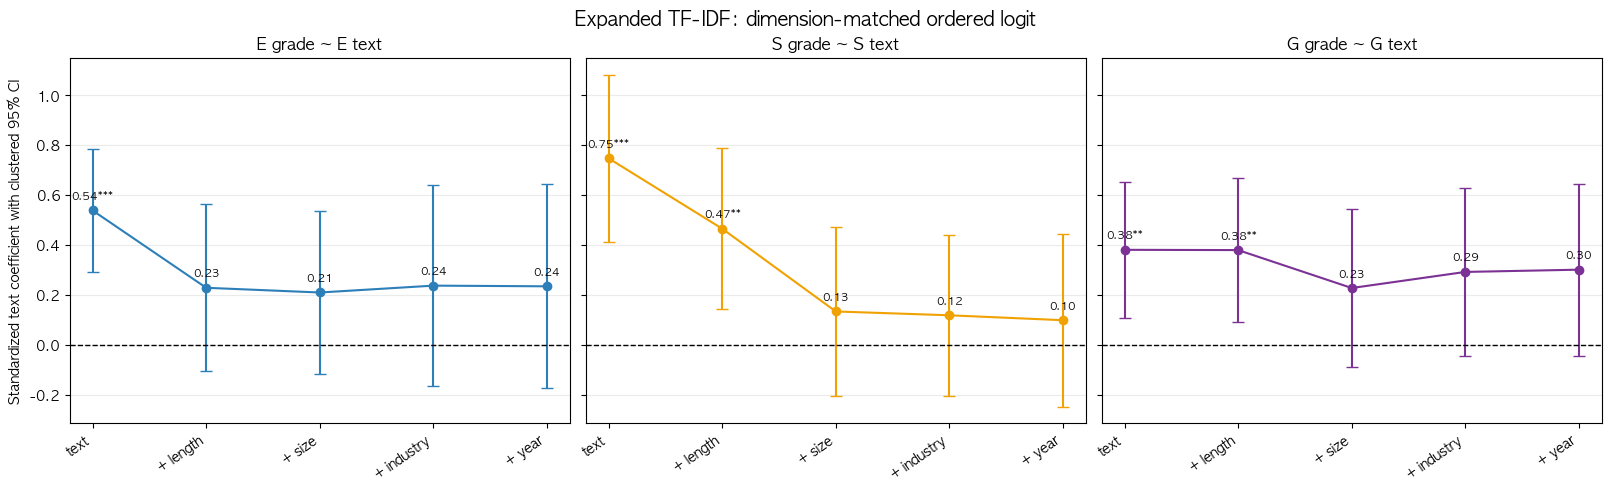

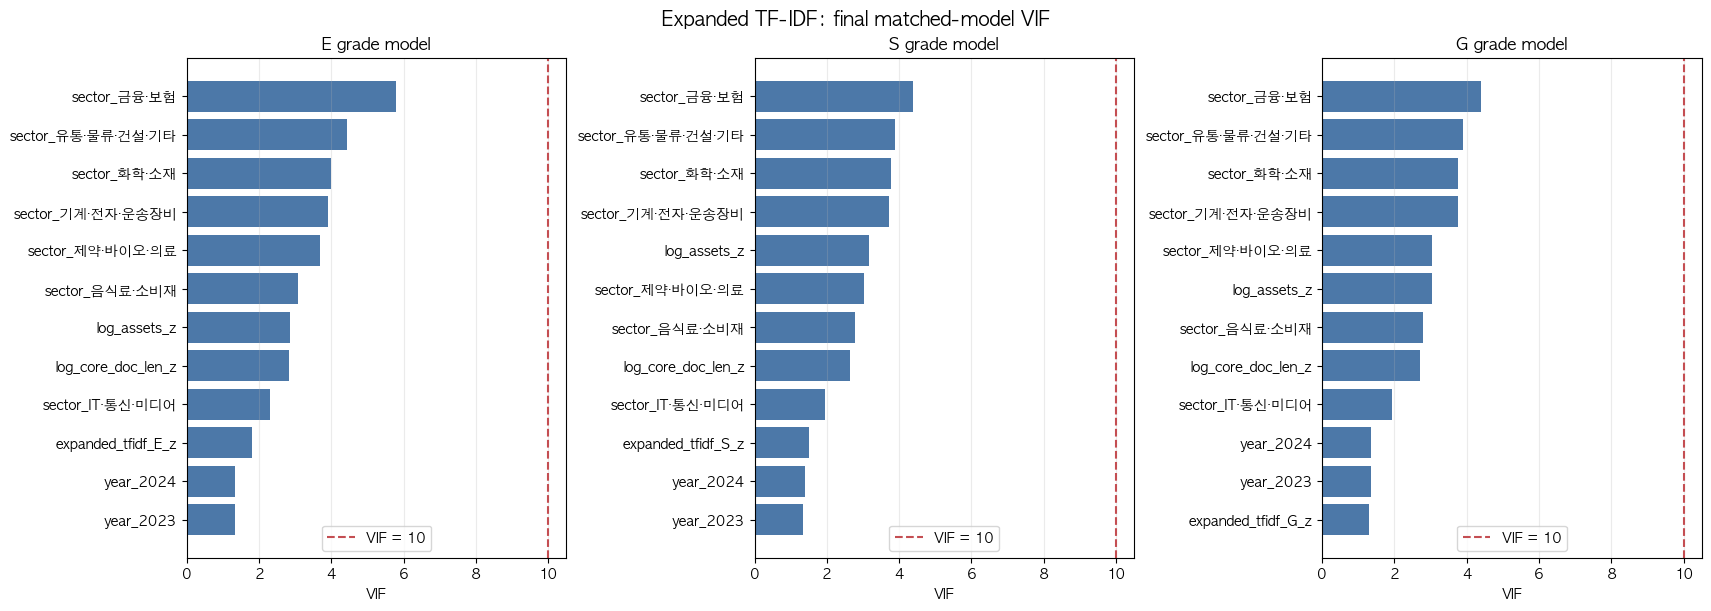


===== 통합 ESG 회귀: E + S + G 점수 계수 변화 =====


spec,term,coef,std_err_clustered,ci_low,ci_high,p_value,significance,aic
01_text_only,expanded_tfidf_E_z,0.366,0.142,0.088,0.644,0.00988,**,1216.1
01_text_only,expanded_tfidf_S_z,0.594,0.177,0.246,0.941,0.000808,***,1216.1
01_text_only,expanded_tfidf_G_z,0.153,0.172,-0.184,0.489,0.374,,1216.1
02_add_length,expanded_tfidf_E_z,0.166,0.155,-0.137,0.469,0.284,,1088.2
02_add_length,expanded_tfidf_S_z,0.257,0.168,-0.072,0.585,0.126,,1088.2
02_add_length,expanded_tfidf_G_z,0.299,0.180,-0.053,0.651,0.0964,,1088.2
03_add_size,expanded_tfidf_E_z,0.163,0.158,-0.146,0.472,0.302,,1058.4
03_add_size,expanded_tfidf_S_z,0.134,0.175,-0.208,0.476,0.443,,1058.4
03_add_size,expanded_tfidf_G_z,0.125,0.175,-0.219,0.468,0.478,,1058.4
04_add_industry,expanded_tfidf_E_z,0.359,0.210,-0.053,0.770,0.0876,,1038.7



===== 통합 ESG 최종 사양(05_add_year) 전체 계수 =====


spec,term,term_type,coef,std_err_clustered,ci_low,ci_high,p_value,significance
05_add_year,expanded_tfidf_E_z,text_score,0.364,0.211,-0.049,0.778,0.0843,
05_add_year,expanded_tfidf_S_z,text_score,0.161,0.196,-0.222,0.544,0.41,
05_add_year,expanded_tfidf_G_z,text_score,0.212,0.193,-0.167,0.591,0.273,
05_add_year,log_core_doc_len_z,length,0.753,0.300,0.166,1.341,0.012,*
05_add_year,log_assets_z,size,0.974,0.405,0.179,1.768,0.0163,*
05_add_year,sector_IT·통신·미디어,industry,2.708,0.761,1.215,4.200,0.000376,***
05_add_year,sector_금융·보험,industry,0.983,0.668,-0.326,2.292,0.141,
05_add_year,sector_기계·전자·운송장비,industry,1.325,0.633,0.084,2.565,0.0363,*
05_add_year,sector_유통·물류·건설·기타,industry,1.610,0.669,0.299,2.921,0.0161,*
05_add_year,sector_음식료·소비재,industry,0.531,0.611,-0.666,1.729,0.385,


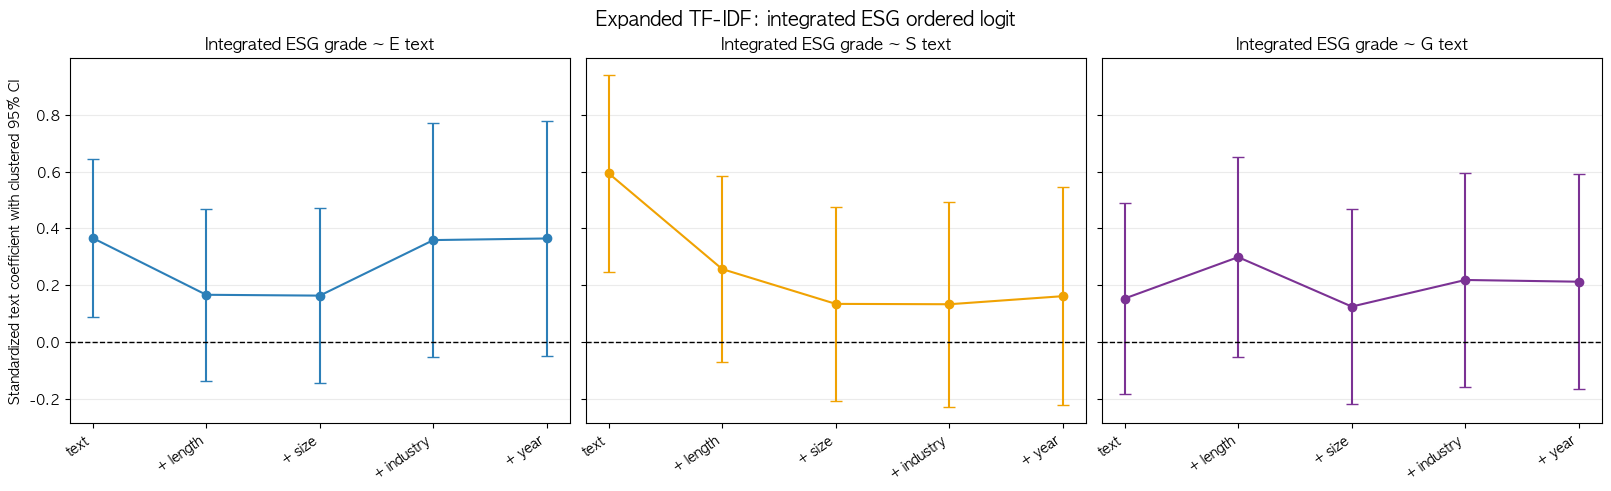

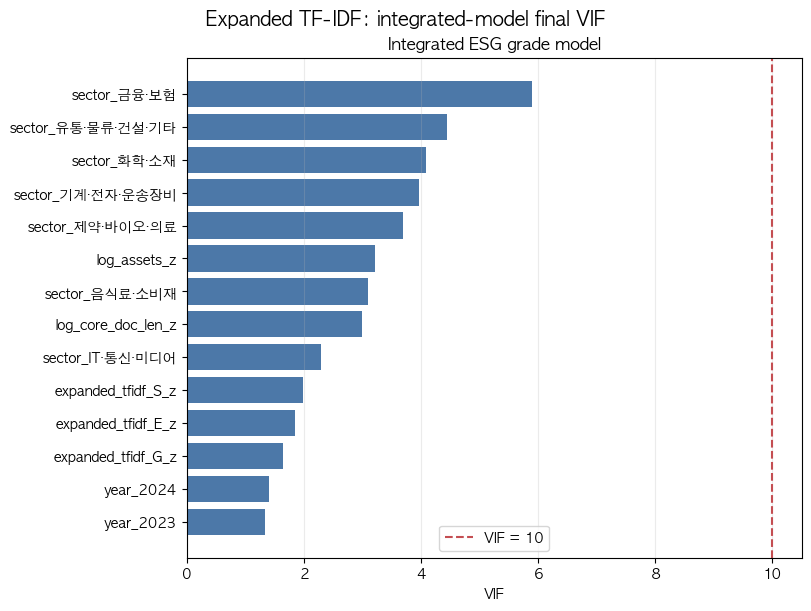

저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_matched_ordered_logit_summary.csv
저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_matched_ordered_logit_text_effects.csv
저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_matched_ordered_logit_vif.csv
저장 완료: /Users/home1/esg-dart-project/reports/figures/05c_expanded_tfidf_matched_ordered_logit_text_effects.png
저장 완료: /Users/home1/esg-dart-project/reports/figures/05c_expanded_tfidf_matched_ordered_logit_final_vif.png
저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_integrated_ordered_logit_summary.csv
저장 완료: /Users/home1/esg-dart-project/data/processed/05c_expanded_tfidf_integrated_ordered_logit_vif.csv
저장 완료: /Users/home1/esg-dart-project/reports/figures/05c_expanded_tfidf_integrated_ordered_logit_text_effects.png
저장 완료: /Users/home1/esg-dart-project/reports/figures/05c_expanded_tfidf_integrated_ordered_logit_final_vif.png


In [24]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

INDUSTRY_SECTOR_MAPPING_CSV = DATA_PROCESSED / 'industry_sector_mapping.csv'
SECTION_LENGTHS_CSV = DATA_PROCESSED / 'dart_section_lengths.csv'

MATCHED_OUTPUT_PREFIX = '05c_expanded_tfidf'
OUTPUT_MATCHED_REGRESSION_SUMMARY = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_summary.csv'
OUTPUT_MATCHED_TEXT_EFFECTS = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_text_effects.csv'
OUTPUT_MATCHED_VIF = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_vif.csv'
OUTPUT_MATCHED_SUMMARY_DIR = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_summaries'
OUTPUT_MATCHED_EFFECT_PLOT = FIGURES_DIR / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_text_effects.png'
OUTPUT_MATCHED_VIF_PLOT = FIGURES_DIR / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_final_vif.png'
OUTPUT_INTEGRATED_REGRESSION_SUMMARY = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_integrated_ordered_logit_summary.csv'
OUTPUT_INTEGRATED_VIF = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_integrated_ordered_logit_vif.csv'
OUTPUT_INTEGRATED_SUMMARY_DIR = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_integrated_ordered_logit_summaries'
OUTPUT_INTEGRATED_EFFECT_PLOT = FIGURES_DIR / f'{MATCHED_OUTPUT_PREFIX}_integrated_ordered_logit_text_effects.png'
OUTPUT_INTEGRATED_VIF_PLOT = FIGURES_DIR / f'{MATCHED_OUTPUT_PREFIX}_integrated_ordered_logit_final_vif.png'
OUTPUT_MATCHED_SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_INTEGRATED_SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

for path in [INDUSTRY_SECTOR_MAPPING_CSV, SECTION_LENGTHS_CSV]:
    assert path.exists(), f'통제변수 입력 파일 누락: {path}'


def normalize_stock_code(series: pd.Series) -> pd.Series:
    return series.astype('string').str.replace(r'\.0$', '', regex=True).str.zfill(6)


def zscore(series: pd.Series) -> pd.Series:
    std = series.std(ddof=0)
    assert std > 0, f'표준화할 변수의 표준편차가 0입니다: {series.name}'
    return (series - series.mean()) / std


def pvalue_stars_for_matched_regression(pval: float) -> str:
    if pd.isna(pval):
        return ''
    if pval < 0.001:
        return '***'
    if pval < 0.01:
        return '**'
    if pval < 0.05:
        return '*'
    return ''


industry_sector_mapping = pd.read_csv(
    INDUSTRY_SECTOR_MAPPING_CSV,
    dtype={'stock_code': 'string'},
)
section_lengths = pd.read_csv(
    SECTION_LENGTHS_CSV,
    dtype={'stock_code': 'string'},
)

required_industry_cols = {'stock_code', 'fiscal_year', 'sector', 'log_assets'}
required_length_cols = {'stock_code', 'fiscal_year', 'esg_year', 'len_II', 'len_IV', 'len_VI'}
assert required_industry_cols <= set(industry_sector_mapping.columns), (
    f'업종 매핑 필수 컬럼 누락: {required_industry_cols - set(industry_sector_mapping.columns)}'
)
assert required_length_cols <= set(section_lengths.columns), (
    f'문서 길이 필수 컬럼 누락: {required_length_cols - set(section_lengths.columns)}'
)

industry_sector_mapping['stock_code'] = normalize_stock_code(industry_sector_mapping['stock_code'])
industry_sector_mapping['fiscal_year'] = industry_sector_mapping['fiscal_year'].astype(int)
section_lengths['stock_code'] = normalize_stock_code(section_lengths['stock_code'])
section_lengths['fiscal_year'] = section_lengths['fiscal_year'].astype(int)
section_lengths['esg_year'] = section_lengths['esg_year'].astype(int)

assert industry_sector_mapping.duplicated(KEY_COLS).sum() == 0, '업종 매핑의 PK 중복이 있습니다.'
assert section_lengths.duplicated(STRICT_KEY_COLS).sum() == 0, '문서 길이의 strict PK 중복이 있습니다.'

matched_panel = merged.merge(
    industry_sector_mapping[['stock_code', 'fiscal_year', 'sector', 'log_assets']],
    on=KEY_COLS,
    how='left',
    validate='one_to_one',
    indicator='_industry_merge',
)
matched_panel = matched_panel.merge(
    section_lengths[STRICT_KEY_COLS + ['len_II', 'len_IV', 'len_VI']],
    on=STRICT_KEY_COLS,
    how='left',
    validate='one_to_one',
    indicator='_length_merge',
)

assert matched_panel['_industry_merge'].eq('both').all(), '업종·자산 통제 merge 누락이 있습니다.'
assert matched_panel['_length_merge'].eq('both').all(), '문서 길이 통제 merge 누락이 있습니다.'
matched_panel = matched_panel.drop(columns=['_industry_merge', '_length_merge'])

matched_panel['core_doc_len'] = matched_panel[['len_II', 'len_IV', 'len_VI']].sum(axis=1)
assert matched_panel['core_doc_len'].gt(0).all(), 'core 문서 길이가 0 이하인 행이 있습니다.'
matched_panel['log_core_doc_len'] = np.log1p(matched_panel['core_doc_len'])

required_panel_cols = ['sector', 'log_assets', 'log_core_doc_len'] + GRADE_NUM_COLS + REGRESSION_FEATURES
assert matched_panel[required_panel_cols].notna().all().all(), '최종 회귀 변수에 결측이 있습니다.'
assert len(matched_panel) == len(merged), '통제 merge 후 행 수가 달라졌습니다.'

MATCHED_TEXT_FEATURES = dict(zip(ESG_DIMS, REGRESSION_FEATURES))
MATCHED_GRADE_TARGETS = {
    'E': 'e_grade_num',
    'S': 's_grade_num',
    'G': 'g_grade_num',
}

for text_col in MATCHED_TEXT_FEATURES.values():
    matched_panel[f'{text_col}_z'] = zscore(matched_panel[text_col])
matched_panel['log_core_doc_len_z'] = zscore(matched_panel['log_core_doc_len'])
matched_panel['log_assets_z'] = zscore(matched_panel['log_assets'])

sector_dummies = pd.get_dummies(matched_panel['sector'], prefix='sector', drop_first=True, dtype=float)
year_dummies = pd.get_dummies(matched_panel['fiscal_year'], prefix='year', drop_first=True, dtype=float)
matched_panel = pd.concat([matched_panel, sector_dummies, year_dummies], axis=1)

included_sectors = {col.removeprefix('sector_') for col in sector_dummies.columns}
included_years = {int(col.removeprefix('year_')) for col in year_dummies.columns}
reference_sector = sorted(set(matched_panel['sector']) - included_sectors)
reference_year = sorted(set(matched_panel['fiscal_year']) - included_years)
assert len(reference_sector) == 1, f'업종 기준 범주 확정 실패: {reference_sector}'
assert len(reference_year) == 1, f'연도 기준 범주 확정 실패: {reference_year}'

CONTROL_BLOCKS = {
    '01_text_only': [],
    '02_add_length': ['log_core_doc_len_z'],
    '03_add_size': ['log_core_doc_len_z', 'log_assets_z'],
    '04_add_industry': ['log_core_doc_len_z', 'log_assets_z'] + list(sector_dummies.columns),
    '05_add_year': (
        ['log_core_doc_len_z', 'log_assets_z']
        + list(sector_dummies.columns)
        + list(year_dummies.columns)
    ),
}

print('최종 차원별 매칭 회귀 패널 shape:', matched_panel.shape)
print('기업 cluster 수:', matched_panel['stock_code'].nunique())
print('업종 더미 기준 범주:', reference_sector[0])
print('연도 더미 기준 범주:', reference_year[0])
print('통제변수 추가 순서:', list(CONTROL_BLOCKS))
print('\n차원별 회귀식:')
for dim in ESG_DIMS:
    print(f'{dim}_grade ~ {MATCHED_TEXT_FEATURES[dim]} + [길이 + 규모 + 업종 + 연도]')


def calculate_vif_for_matched_model(
    data: pd.DataFrame,
    predictors: list[str],
    dimension: str,
    spec_name: str,
) -> pd.DataFrame:
    vif_design = sm.add_constant(data[predictors].astype(float), has_constant='add')
    rows = []
    for idx, term in enumerate(vif_design.columns):
        if term == 'const':
            continue
        rows.append({
            'dimension': dimension,
            'spec': spec_name,
            'term': term,
            'vif': variance_inflation_factor(vif_design.to_numpy(), idx),
        })
    return pd.DataFrame(rows)


matched_regression_rows = []
matched_vif_frames = []
cluster_groups = matched_panel['stock_code']

for dimension in ESG_DIMS:
    text_feature_z = f'{MATCHED_TEXT_FEATURES[dimension]}_z'
    target_grade_num = MATCHED_GRADE_TARGETS[dimension]
    model_y = matched_panel[target_grade_num].astype(int)

    for spec_name, controls in CONTROL_BLOCKS.items():
        predictors = [text_feature_z] + controls
        model_X = matched_panel[predictors].astype(float)
        matched_vif_frames.append(
            calculate_vif_for_matched_model(matched_panel, predictors, dimension, spec_name)
        )

        ordered_model = OrderedModel(model_y, model_X, distr='logit')
        ordered_result = ordered_model.fit(
            method='bfgs',
            disp=False,
            cov_type='cluster',
            cov_kwds={'groups': cluster_groups},
        )
        assert ordered_result.cov_type == 'cluster', '기업별 cluster standard error 적용 실패'
        (OUTPUT_MATCHED_SUMMARY_DIR / f'{dimension}_{spec_name}_ordered_logit_summary.txt').write_text(
            ordered_result.summary().as_text(),
            encoding='utf-8',
        )

        for term in predictors:
            matched_regression_rows.append({
                'dimension': dimension,
                'target_grade_num': target_grade_num,
                'spec': spec_name,
                'term': term,
                'term_type': (
                    'text_score' if term == text_feature_z
                    else 'length' if term == 'log_core_doc_len_z'
                    else 'size' if term == 'log_assets_z'
                    else 'industry' if term.startswith('sector_')
                    else 'year'
                ),
                'coef': ordered_result.params[term],
                'std_err_clustered': ordered_result.bse[term],
                'p_value': ordered_result.pvalues[term],
                'aic': ordered_result.aic,
                'n_obs': int(ordered_result.nobs),
                'n_clusters': matched_panel['stock_code'].nunique(),
            })

matched_regression_summary = pd.DataFrame(matched_regression_rows)
matched_regression_summary['ci_low'] = (
    matched_regression_summary['coef'] - 1.96 * matched_regression_summary['std_err_clustered']
)
matched_regression_summary['ci_high'] = (
    matched_regression_summary['coef'] + 1.96 * matched_regression_summary['std_err_clustered']
)
matched_regression_summary['significance'] = matched_regression_summary['p_value'].map(
    pvalue_stars_for_matched_regression
)
matched_regression_summary.to_csv(
    OUTPUT_MATCHED_REGRESSION_SUMMARY,
    index=False,
    encoding='utf-8-sig',
)

matched_text_effects = matched_regression_summary.loc[
    matched_regression_summary['term_type'] == 'text_score'
].copy()
matched_text_effects.to_csv(OUTPUT_MATCHED_TEXT_EFFECTS, index=False, encoding='utf-8-sig')

matched_vif = pd.concat(matched_vif_frames, ignore_index=True)
matched_vif.to_csv(OUTPUT_MATCHED_VIF, index=False, encoding='utf-8-sig')

print('\n===== 같은 차원 텍스트 점수 계수 변화 =====')
display(
    matched_text_effects[
        [
            'dimension', 'spec', 'term', 'coef', 'std_err_clustered',
            'ci_low', 'ci_high', 'p_value', 'significance', 'aic', 'n_obs', 'n_clusters',
        ]
    ]
    .style
    .format({
        'coef': '{:.3f}', 'std_err_clustered': '{:.3f}',
        'ci_low': '{:.3f}', 'ci_high': '{:.3f}', 'p_value': '{:.3g}', 'aic': '{:.1f}',
    })
    .background_gradient(cmap='Blues', subset=['coef'])
    .hide(axis='index')
)

print('\n===== 최종 사양(05_add_year) 전체 계수 =====')
for dimension in ESG_DIMS:
    final_coef_view = matched_regression_summary.loc[
        (matched_regression_summary['dimension'] == dimension)
        & (matched_regression_summary['spec'] == '05_add_year'),
        [
            'dimension', 'spec', 'term', 'term_type', 'coef', 'std_err_clustered',
            'ci_low', 'ci_high', 'p_value', 'significance',
        ],
    ].reset_index(drop=True)
    print(f'\n[{dimension}_grade] 같은 차원 점수 + 길이 + 규모 + 업종 + 연도')
    display(
        final_coef_view.style
        .format({
            'coef': '{:.3f}', 'std_err_clustered': '{:.3f}',
            'ci_low': '{:.3f}', 'ci_high': '{:.3f}', 'p_value': '{:.3g}',
        })
        .background_gradient(cmap='Blues', subset=['coef'])
        .hide(axis='index')
    )

print('\n===== VIF 최대값: 차원별·사양별 =====')
matched_vif_max = matched_vif.groupby(['dimension', 'spec'], as_index=False)['vif'].max()
display(matched_vif_max.style.format({'vif': '{:.2f}'}).background_gradient(cmap='Reds', subset=['vif']))

# 같은 차원 점수의 통제변수 추가 전후 변화
SPEC_ORDER = list(CONTROL_BLOCKS)
DIMENSION_COLORS = {'E': '#2C7FB8', 'S': '#F0A202', 'G': '#7B3294'}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True, constrained_layout=True)
for ax, dimension in zip(axes, ESG_DIMS):
    plot_df = matched_text_effects.loc[
        matched_text_effects['dimension'] == dimension
    ].set_index('spec').reindex(SPEC_ORDER).reset_index()
    x_positions = np.arange(len(plot_df))
    ax.errorbar(
        x_positions,
        plot_df['coef'],
        yerr=[
            plot_df['coef'] - plot_df['ci_low'],
            plot_df['ci_high'] - plot_df['coef'],
        ],
        fmt='o-',
        capsize=4,
        color=DIMENSION_COLORS[dimension],
    )
    for x_pos, row in zip(x_positions, plot_df.itertuples(index=False)):
        ax.annotate(
            f'{row.coef:.2f}{row.significance}',
            (x_pos, row.coef),
            xytext=(0, 8),
            textcoords='offset points',
            ha='center',
            fontsize=8,
        )
    ax.axhline(0, color='black', ls='--', lw=1)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(['text', '+ length', '+ size', '+ industry', '+ year'], rotation=35, ha='right')
    ax.set_title(f'{dimension} grade ~ {dimension} text')
    ax.grid(axis='y', alpha=0.25)
axes[0].set_ylabel('Standardized text coefficient with clustered 95% CI')
fig.suptitle('Expanded TF-IDF: dimension-matched ordered logit', fontsize=14)
fig.savefig(OUTPUT_MATCHED_EFFECT_PLOT, dpi=200, bbox_inches='tight')
plt.show()

# 최종 사양 VIF
fig, axes = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
for ax, dimension in zip(axes, ESG_DIMS):
    plot_vif = matched_vif.loc[
        (matched_vif['dimension'] == dimension) & (matched_vif['spec'] == '05_add_year')
    ].sort_values('vif', ascending=True)
    colors = ['#C44E52' if value >= 10 else '#4C78A8' for value in plot_vif['vif']]
    ax.barh(plot_vif['term'], plot_vif['vif'], color=colors)
    ax.axvline(10, color='#C44E52', ls='--', lw=1.5, label='VIF = 10')
    ax.set_title(f'{dimension} grade model')
    ax.set_xlabel('VIF')
    ax.legend()
    ax.grid(axis='x', alpha=0.25)
fig.suptitle('Expanded TF-IDF: final matched-model VIF', fontsize=14)
fig.savefig(OUTPUT_MATCHED_VIF_PLOT, dpi=200, bbox_inches='tight')
plt.show()

# 통합 ESG 등급: E/S/G 점수를 함께 넣고 같은 통제변수 추가 경로를 비교한다.
integrated_regression_rows = []
integrated_vif_frames = []
integrated_text_features_z = [f'{MATCHED_TEXT_FEATURES[dim]}_z' for dim in ESG_DIMS]
integrated_y = matched_panel[INTEGRATED_GRADE_NUM_COL].astype(int)

for spec_name, controls in CONTROL_BLOCKS.items():
    predictors = integrated_text_features_z + controls
    model_X = matched_panel[predictors].astype(float)
    integrated_vif_frames.append(
        calculate_vif_for_matched_model(matched_panel, predictors, 'Integrated ESG', spec_name)
    )

    integrated_model = OrderedModel(integrated_y, model_X, distr='logit')
    integrated_result = integrated_model.fit(
        method='bfgs',
        disp=False,
        cov_type='cluster',
        cov_kwds={'groups': cluster_groups},
    )
    assert integrated_result.cov_type == 'cluster', '통합 회귀 cluster standard error 적용 실패'
    (OUTPUT_INTEGRATED_SUMMARY_DIR / f'{spec_name}_ordered_logit_summary.txt').write_text(
        integrated_result.summary().as_text(),
        encoding='utf-8',
    )

    for term in predictors:
        integrated_regression_rows.append({
            'spec': spec_name,
            'target_grade_num': INTEGRATED_GRADE_NUM_COL,
            'term': term,
            'term_type': (
                'text_score' if term in integrated_text_features_z
                else 'length' if term == 'log_core_doc_len_z'
                else 'size' if term == 'log_assets_z'
                else 'industry' if term.startswith('sector_')
                else 'year'
            ),
            'coef': integrated_result.params[term],
            'std_err_clustered': integrated_result.bse[term],
            'p_value': integrated_result.pvalues[term],
            'aic': integrated_result.aic,
            'n_obs': int(integrated_result.nobs),
            'n_clusters': matched_panel['stock_code'].nunique(),
        })

integrated_regression_summary = pd.DataFrame(integrated_regression_rows)
integrated_regression_summary['ci_low'] = (
    integrated_regression_summary['coef'] - 1.96 * integrated_regression_summary['std_err_clustered']
)
integrated_regression_summary['ci_high'] = (
    integrated_regression_summary['coef'] + 1.96 * integrated_regression_summary['std_err_clustered']
)
integrated_regression_summary['significance'] = integrated_regression_summary['p_value'].map(
    pvalue_stars_for_matched_regression
)
integrated_regression_summary.to_csv(
    OUTPUT_INTEGRATED_REGRESSION_SUMMARY,
    index=False,
    encoding='utf-8-sig',
)
integrated_vif = pd.concat(integrated_vif_frames, ignore_index=True)
integrated_vif.to_csv(OUTPUT_INTEGRATED_VIF, index=False, encoding='utf-8-sig')

print('\n===== 통합 ESG 회귀: E + S + G 점수 계수 변화 =====')
integrated_text_effects = integrated_regression_summary.loc[
    integrated_regression_summary['term_type'] == 'text_score'
].copy()
display(
    integrated_text_effects[
        ['spec', 'term', 'coef', 'std_err_clustered', 'ci_low', 'ci_high', 'p_value', 'significance', 'aic']
    ]
    .style
    .format({
        'coef': '{:.3f}', 'std_err_clustered': '{:.3f}',
        'ci_low': '{:.3f}', 'ci_high': '{:.3f}', 'p_value': '{:.3g}', 'aic': '{:.1f}',
    })
    .background_gradient(cmap='Blues', subset=['coef'])
    .hide(axis='index')
)

print('\n===== 통합 ESG 최종 사양(05_add_year) 전체 계수 =====')
display(
    integrated_regression_summary.loc[
        integrated_regression_summary['spec'] == '05_add_year',
        ['spec', 'term', 'term_type', 'coef', 'std_err_clustered', 'ci_low', 'ci_high', 'p_value', 'significance'],
    ]
    .style
    .format({
        'coef': '{:.3f}', 'std_err_clustered': '{:.3f}',
        'ci_low': '{:.3f}', 'ci_high': '{:.3f}', 'p_value': '{:.3g}',
    })
    .background_gradient(cmap='Blues', subset=['coef'])
    .hide(axis='index')
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True, constrained_layout=True)
for ax, dimension in zip(axes, ESG_DIMS):
    term = f'{MATCHED_TEXT_FEATURES[dimension]}_z'
    plot_df = integrated_text_effects.loc[
        integrated_text_effects['term'] == term
    ].set_index('spec').reindex(SPEC_ORDER).reset_index()
    x_positions = np.arange(len(plot_df))
    ax.errorbar(
        x_positions,
        plot_df['coef'],
        yerr=[plot_df['coef'] - plot_df['ci_low'], plot_df['ci_high'] - plot_df['coef']],
        fmt='o-',
        capsize=4,
        color=DIMENSION_COLORS[dimension],
    )
    ax.axhline(0, color='black', ls='--', lw=1)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(['text', '+ length', '+ size', '+ industry', '+ year'], rotation=35, ha='right')
    ax.set_title(f'Integrated ESG grade ~ {dimension} text')
    ax.grid(axis='y', alpha=0.25)
axes[0].set_ylabel('Standardized text coefficient with clustered 95% CI')
fig.suptitle('Expanded TF-IDF: integrated ESG ordered logit', fontsize=14)
fig.savefig(OUTPUT_INTEGRATED_EFFECT_PLOT, dpi=200, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
plot_integrated_vif = integrated_vif.loc[
    integrated_vif['spec'] == '05_add_year'
].sort_values('vif', ascending=True)
colors = ['#C44E52' if value >= 10 else '#4C78A8' for value in plot_integrated_vif['vif']]
ax.barh(plot_integrated_vif['term'], plot_integrated_vif['vif'], color=colors)
ax.axvline(10, color='#C44E52', ls='--', lw=1.5, label='VIF = 10')
ax.set_title('Integrated ESG grade model')
ax.set_xlabel('VIF')
ax.legend()
ax.grid(axis='x', alpha=0.25)
fig.suptitle('Expanded TF-IDF: integrated-model final VIF', fontsize=14)
fig.savefig(OUTPUT_INTEGRATED_VIF_PLOT, dpi=200, bbox_inches='tight')
plt.show()

for path in [
    OUTPUT_MATCHED_REGRESSION_SUMMARY,
    OUTPUT_MATCHED_TEXT_EFFECTS,
    OUTPUT_MATCHED_VIF,
    OUTPUT_MATCHED_EFFECT_PLOT,
    OUTPUT_MATCHED_VIF_PLOT,
    OUTPUT_INTEGRATED_REGRESSION_SUMMARY,
    OUTPUT_INTEGRATED_VIF,
    OUTPUT_INTEGRATED_EFFECT_PLOT,
    OUTPUT_INTEGRATED_VIF_PLOT,
]:
    assert path.exists(), f'최종 차원별 매칭 회귀 산출물 저장 실패: {path}'
    print('저장 완료:', path)


### 해석 가이드

- 핵심은 각 차원의 같은 점수 계수다: `E grade ~ E text`, `S grade ~ S text`, `G grade ~ G text`.
- `01_text_only -> 05_add_year`로 이동할 때 계수가 얼마나 줄고 유의성이 어떻게 바뀌는지 본다.
- 길이를 추가한 직후 계수가 크게 줄면 문서 분량 효과가 섞였을 가능성이 있다.
- 규모·업종·연도를 추가한 뒤에도 계수가 유지되면 같은 영역의 disclosure signal 근거가 된다.
- VIF가 10 이상이면 다중공선성 검토가 필요하다.
- 통제 관찰 연구이므로 계수를 인과효과로 해석하지 않는다.


In [25]:
# 확장 TF-IDF OLS: 통제변수 미포함 / 포함 요약표만 비교
expanded_ols_text_features = list(REGRESSION_FEATURES)
expanded_ols_controls = CONTROL_BLOCKS['05_add_year']
expanded_ols_y = matched_panel[INTEGRATED_GRADE_NUM_COL].astype(float)

expanded_ols_X_without_controls = sm.add_constant(
    matched_panel[expanded_ols_text_features].astype(float),
    has_constant='add',
)
expanded_ols_without_controls = sm.OLS(
    expanded_ols_y,
    expanded_ols_X_without_controls,
).fit(cov_type='HC3')

expanded_ols_X_with_controls = sm.add_constant(
    matched_panel[expanded_ols_text_features + expanded_ols_controls].astype(float),
    has_constant='add',
)
expanded_ols_with_controls = sm.OLS(
    expanded_ols_y,
    expanded_ols_X_with_controls,
).fit(cov_type='HC3')

print('===== OLS 1. 확장 TF-IDF: 통제변수 없음 =====')
print(expanded_ols_without_controls.summary())

print('\n===== OLS 2. 확장 TF-IDF: 길이 + 규모 + 업종 + 연도 통제 =====')
print(expanded_ols_with_controls.summary())


===== OLS 1. 확장 TF-IDF: 통제변수 없음 =====
                            OLS Regression Results                            
Dep. Variable:          esg_grade_num   R-squared:                       0.208
Model:                            OLS   Adj. R-squared:                  0.202
Method:                 Least Squares   F-statistic:                     41.30
Date:                Sun, 31 May 2026   Prob (F-statistic):           4.27e-23
Time:                        19:44:14   Log-Likelihood:                -680.28
No. Observations:                 381   AIC:                             1369.
Df Residuals:                     377   BIC:                             1384.
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
co